# Urdu Sarcasm Detection — DS5007 NLP, Programming Assignment 1

**Task.** Binary classification of Urdu social-media posts: `is_sarcastic` = 1 (sarcastic) / 0 (non-sarcastic).

**What is special about this solution**

* **Emojis are treated as meaning, not noise.** 80 % of the posts contain emojis. A curated lexicon
  (`src/emoji_semantics.py`) gives every emoji an English name, an **Urdu gloss**, a sentiment polarity,
  a pragmatic category (LAUGH, TEASE, SMIRK, THINK, LOVE, SAD, ANGER, PRAYER, PRAISE, FLOWER, SHY, GESTURE, INSULT)
  and an *irony-cue* flag. The lexicon feeds (i) token rewriting for n-gram models, (ii) an Urdu-gloss
  input mode for the transformer, (iii) dense features such as **word–emoji polarity contrast**
  (praise words + 😂/🙄) and (iv) a data-driven emoji sarcasm prior learnt on the training split only.
* **Urdu-aware preprocessing** that is conservative and fully ablated: Arabic/Urdu code-point unification,
  diacritic removal, keyboard spelling fixes (ھے→ہے), hashtag reconstruction (ووٹ_کو_عزت_دو), laughter
  and elongation normalisation — while *keeping* punctuation, repetition, Roman/English tokens and Punjabi.
* **Hand-crafted Urdu phrase features** (bonus): ironic-praise markers (واہ, ماشاءاللہ, کیا بات ہے …) and
  ~35 idioms (اپنے پیر پر کلہاڑی, چراغ تلے اندھیرا, ٹوپی ڈرامہ …).
* Three model families: **TF-IDF (LR / SVM / NB)**, **TextCNN & BiLSTM+attention (PyTorch)**, **XLM-RoBERTa fine-tuning**,
  compared with Macro-F1, plus a **5-fold cross-validated ablation study** and a linguistic **error analysis**.

> The notebook is self-contained: section 1 writes the `src/` package to disk, so it runs on Google Colab
> (Runtime → GPU recommended for sections 6–7) or locally (`pip install -r requirements.txt`).

## 0. Setup

In [1]:
import sys, subprocess, importlib
def _ensure(pkgs):
    missing = [p for p in pkgs if importlib.util.find_spec(p.split('==')[0].replace('-', '_')) is None]
    if missing:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
_ensure(['emoji', 'scikit-learn', 'pandas', 'matplotlib', 'joblib', 'tabulate'])
_ensure(['torch', 'transformers', 'sentencepiece'])   # for sections 6-7

import os, json, re, time, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.max_colwidth', 160); pd.set_option('display.width', 220)
os.makedirs('src', exist_ok=True); os.makedirs('outputs/figures', exist_ok=True)
RUN_TRANSFORMER = True          # set False to skip section 7 (needs a GPU; ~10 min on a T4)
SEED = 42

### 0.1 Load the dataset
On Colab you will be prompted to upload `urdu_sarcastic_dataset.csv` (columns `urdu_text`, `is_sarcastic`).
Locally the file is read from `data/`.

In [2]:
DATA_PATH = None
for cand in ['data/urdu_sarcastic_dataset.csv', '../data/urdu_sarcastic_dataset.csv', 'urdu_sarcastic_dataset.csv']:
    if os.path.exists(cand):
        DATA_PATH = cand; break
if DATA_PATH is None:
    try:
        from google.colab import files
        print('Please upload urdu_sarcastic_dataset.csv'); up = files.upload()
        DATA_PATH = list(up.keys())[0]
    except ImportError:
        raise FileNotFoundError('put urdu_sarcastic_dataset.csv in data/')
raw = pd.read_csv(DATA_PATH, encoding='utf-8')
print(raw.shape); raw.head()

(20004, 8)


,urdu_text,is_sarcastic,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7
0,🤣😂😂 ہو لینے دے میری شادی فسادن ٹھیک ہے کوجی نہیں چاہیے 😐😐😐🤣,1,NaN,NaN,NaN,NaN,NaN,NaN
1,چل مہمانوں میں کھانا سرو کر چڑیل چاچی نوں دسدی آں میں😂😂,1,NaN,NaN,NaN,NaN,NaN,NaN
2,کامران خان آپکی دن بھریہ زمہ داری لگائی گئی اپوزیشن کی کردار کشی اوراس پربھونکناہےآپ خوشامدگری وچاپلوسی سےاورکتنی دولت کماناچاہتےہیں موٹرسائیکل سےپیجارو پرا...,0,NaN,NaN,NaN,NaN,NaN,NaN
3,نہیں پائین 😎,0,NaN,NaN,NaN,NaN,NaN,NaN
4,`` مراد علی شاہ کے بھیس میں ڈی جی آئی ایس آئی تھے '' حامد میر😁,1,NaN,NaN,NaN,NaN,NaN,NaN


## 1. The `src` package (written to disk so the notebook is self-contained)

Each cell below is one module. They are shown in full because the design decisions in them are part of the
assignment: how emojis are interpreted, how Urdu text is normalised, and which hand-crafted features are extracted.

In [3]:
%%writefile src/__init__.py
# Urdu sarcasm detection package

Overwriting src/__init__.py


### 1.1 Emoji semantics — lexicon, token rewriting, features, data-driven prior

In [4]:
%%writefile src/emoji_semantics.py
# -*- coding: utf-8 -*-
"""
Emoji semantics for Urdu sarcasm detection.

Social-media Urdu relies heavily on emojis (83% of posts in this dataset contain
at least one).  An emoji is not noise: it carries (a) a literal meaning,
(b) a sentiment polarity and (c) a pragmatic function (laughing *at* vs. laughing
*with*, a smirk, an eye-roll).  Sarcasm is often signalled by a *mismatch*
between the words and the emoji (praise + 😂, complaint + 😍, "great job" + 🙄).

This module turns every emoji into something a model can reason about:

    describe(text)         -> list of EmojiInfo (meaning in English + Urdu, polarity, category)
    explain(text)          -> human readable explanation string
    emoji_to_tokens(text)  -> text with emojis rewritten as word-like tokens
    emoji_features(text)   -> dense numeric features (counts, polarity, contrast, position)
    EmojiPrior             -> data-driven sarcasm log-odds per emoji, fitted on TRAIN only
"""
from __future__ import annotations

import math
import re
from collections import Counter
from dataclasses import dataclass
from typing import Dict, List

import emoji as _emoji

# --------------------------------------------------------------------------- #
# 1. Curated lexicon                                                          #
# --------------------------------------------------------------------------- #
# pol : +1 positive, 0 neutral/ambiguous, -1 negative
# cat : coarse pragmatic class used for grouped tokens / counts
# cue : True when the emoji frequently flags irony/mockery in Pakistani Twitter
#       usage (laughing at someone, smirk, eye-roll, tongue-out).
# ur  : short Urdu gloss so the *meaning* of the emoji is available as text.

LEXICON: Dict[str, dict] = {
    # ---- laughter -----------------------------------------------------------
    "😂": dict(en="face with tears of joy",         ur="ہنسی کے آنسو",            pol=+1, cat="LAUGH", cue=True),
    "🤣": dict(en="rolling on the floor laughing",  ur="لوٹ پوٹ ہنسی",            pol=+1, cat="LAUGH", cue=True),
    "😆": dict(en="grinning squinting face",        ur="زور کی ہنسی",             pol=+1, cat="LAUGH", cue=True),
    "😅": dict(en="grinning face with sweat",       ur="شرمندہ ہنسی",             pol=0,  cat="LAUGH", cue=True),
    "😁": dict(en="beaming face with smiling eyes", ur="دانت نکال کر ہنسی",        pol=+1, cat="LAUGH", cue=True),
    "😄": dict(en="grinning face with smiling eyes",ur="کھلی ہنسی",               pol=+1, cat="LAUGH", cue=True),
    "😃": dict(en="grinning face with big eyes",    ur="کھلی ہنسی",               pol=+1, cat="LAUGH", cue=True),
    "😀": dict(en="grinning face",                  ur="ہنسی",                    pol=+1, cat="LAUGH", cue=True),
    "🤭": dict(en="face with hand over mouth",      ur="دبی ہنسی",                pol=0,  cat="LAUGH", cue=True),
    "😹": dict(en="cat with tears of joy",          ur="ہنستی بلی",               pol=+1, cat="LAUGH", cue=True),
    "🫠": dict(en="melting face",                   ur="پگھلتا چہرہ",             pol=0,  cat="LAUGH", cue=True),
    # ---- tongue-out / teasing ----------------------------------------------
    "😜": dict(en="winking face with tongue",       ur="شرارتی چہرہ",             pol=0,  cat="TEASE", cue=True),
    "😝": dict(en="squinting face with tongue",     ur="زبان نکالنا",             pol=0,  cat="TEASE", cue=True),
    "😛": dict(en="face with tongue",               ur="زبان نکالنا",             pol=0,  cat="TEASE", cue=True),
    "😋": dict(en="face savoring food",             ur="مزے لینا",                pol=+1, cat="TEASE", cue=True),
    "😉": dict(en="winking face",                   ur="آنکھ مارنا",              pol=0,  cat="TEASE", cue=True),
    "😎": dict(en="smiling face with sunglasses",   ur="کول / بے پروا",            pol=+1, cat="TEASE", cue=True),
    "🤪": dict(en="zany face",                      ur="پاگل پن",                 pol=0,  cat="TEASE", cue=True),
    # ---- smirk / irony markers ---------------------------------------------
    "😏": dict(en="smirking face",                  ur="طنزیہ مسکراہٹ",            pol=0,  cat="SMIRK", cue=True),
    "🙄": dict(en="face with rolling eyes",         ur="آنکھیں گھمانا / بیزاری",   pol=-1, cat="SMIRK", cue=True),
    "😒": dict(en="unamused face",                  ur="ناخوش / بیزار",            pol=-1, cat="SMIRK", cue=True),
    "🙂": dict(en="slightly smiling face",          ur="ہلکی (اکثر طنزیہ) مسکراہٹ", pol=0,  cat="SMIRK", cue=True),
    "🙃": dict(en="upside-down face",               ur="الٹا چہرہ / طنز",          pol=0,  cat="SMIRK", cue=True),
    "😬": dict(en="grimacing face",                 ur="دانت پیسنا",              pol=-1, cat="SMIRK", cue=True),
    "😑": dict(en="expressionless face",            ur="بے تاثر",                 pol=-1, cat="SMIRK", cue=True),
    "😐": dict(en="neutral face",                   ur="بے تاثر چہرہ",             pol=0,  cat="SMIRK", cue=True),
    "🤡": dict(en="clown face",                     ur="مسخرہ",                   pol=-1, cat="SMIRK", cue=True),
    "🤷": dict(en="person shrugging",               ur="کندھے اچکانا",             pol=0,  cat="SMIRK", cue=True),
    "🤦": dict(en="person facepalming",             ur="ہاتھ ماتھے پر / افسوس",     pol=-1, cat="SMIRK", cue=True),
    "😇": dict(en="smiling face with halo",         ur="معصوم بننا",              pol=0,  cat="SMIRK", cue=True),
    "🤐": dict(en="zipper-mouth face",              ur="منہ بند",                 pol=0,  cat="SMIRK", cue=True),
    "😶": dict(en="face without mouth",             ur="خاموش",                   pol=0,  cat="SMIRK", cue=True),
    # ---- thinking / doubt ---------------------------------------------------
    "🤔": dict(en="thinking face",                  ur="سوچنا / شک",               pol=0,  cat="THINK", cue=True),
    "🧐": dict(en="face with monocle",              ur="غور سے دیکھنا",            pol=0,  cat="THINK", cue=True),
    "🤨": dict(en="face with raised eyebrow",       ur="شک بھری نظر",              pol=0,  cat="THINK", cue=True),
    "😕": dict(en="confused face",                  ur="الجھن",                   pol=-1, cat="THINK", cue=False),
    # ---- love / affection ---------------------------------------------------
    "❤":  dict(en="red heart",                      ur="دل / محبت",                pol=+1, cat="LOVE", cue=False),
    "♥":  dict(en="heart suit",                     ur="دل / محبت",                pol=+1, cat="LOVE", cue=False),
    "💕": dict(en="two hearts",                     ur="محبت",                    pol=+1, cat="LOVE", cue=False),
    "💞": dict(en="revolving hearts",               ur="محبت",                    pol=+1, cat="LOVE", cue=False),
    "💖": dict(en="sparkling heart",                ur="چمکتا دل",                pol=+1, cat="LOVE", cue=False),
    "💗": dict(en="growing heart",                  ur="دل",                      pol=+1, cat="LOVE", cue=False),
    "💓": dict(en="beating heart",                  ur="دھڑکتا دل",               pol=+1, cat="LOVE", cue=False),
    "💘": dict(en="heart with arrow",               ur="عشق",                     pol=+1, cat="LOVE", cue=False),
    "💙": dict(en="blue heart",                     ur="دل",                      pol=+1, cat="LOVE", cue=False),
    "💚": dict(en="green heart",                    ur="دل",                      pol=+1, cat="LOVE", cue=False),
    "💛": dict(en="yellow heart",                   ur="دل",                      pol=+1, cat="LOVE", cue=False),
    "💜": dict(en="purple heart",                   ur="دل",                      pol=+1, cat="LOVE", cue=False),
    "🖤": dict(en="black heart",                    ur="کالا دل",                 pol=0,  cat="LOVE", cue=False),
    "🤍": dict(en="white heart",                    ur="دل",                      pol=+1, cat="LOVE", cue=False),
    "😍": dict(en="smiling face with heart-eyes",   ur="پیار بھری نظر",            pol=+1, cat="LOVE", cue=False),
    "🥰": dict(en="smiling face with hearts",       ur="پیار",                    pol=+1, cat="LOVE", cue=False),
    "😘": dict(en="face blowing a kiss",            ur="بوسہ",                    pol=+1, cat="LOVE", cue=False),
    "😻": dict(en="smiling cat with heart-eyes",    ur="پیار بھری بلی",            pol=+1, cat="LOVE", cue=False),
    "😊": dict(en="smiling face with smiling eyes", ur="مسکراہٹ",                 pol=+1, cat="LOVE", cue=False),
    "☺":  dict(en="smiling face",                   ur="مسکراہٹ",                 pol=+1, cat="LOVE", cue=False),
    "😌": dict(en="relieved face",                  ur="اطمینان",                 pol=+1, cat="LOVE", cue=False),
    # ---- sadness / heartbreak (poetry / shayari register) ------------------
    "💔": dict(en="broken heart",                   ur="ٹوٹا دل",                 pol=-1, cat="SAD", cue=False),
    "😭": dict(en="loudly crying face",             ur="زور سے رونا",              pol=-1, cat="SAD", cue=False),
    "😢": dict(en="crying face",                    ur="رونا",                    pol=-1, cat="SAD", cue=False),
    "😥": dict(en="sad but relieved face",          ur="اداس",                    pol=-1, cat="SAD", cue=False),
    "😔": dict(en="pensive face",                   ur="اداس / فکرمند",            pol=-1, cat="SAD", cue=False),
    "😞": dict(en="disappointed face",              ur="مایوس",                   pol=-1, cat="SAD", cue=False),
    "😣": dict(en="persevering face",               ur="پریشان",                  pol=-1, cat="SAD", cue=False),
    "😩": dict(en="weary face",                     ur="تھکا ہارا",                pol=-1, cat="SAD", cue=False),
    "😫": dict(en="tired face",                     ur="تھکا",                    pol=-1, cat="SAD", cue=False),
    "🥺": dict(en="pleading face",                  ur="التجا",                   pol=-1, cat="SAD", cue=False),
    "😓": dict(en="downcast face with sweat",       ur="اداس / شرمندہ",            pol=-1, cat="SAD", cue=False),
    "🥀": dict(en="wilted flower",                  ur="مرجھایا پھول / اداسی",      pol=-1, cat="SAD", cue=False),
    "🍂": dict(en="fallen leaf",                    ur="گرا پتا / خزاں",           pol=-1, cat="SAD", cue=False),
    "🍁": dict(en="maple leaf",                     ur="خزاں کا پتا",              pol=0,  cat="SAD", cue=False),
    # ---- anger / disgust ----------------------------------------------------
    "😡": dict(en="enraged face",                   ur="غصہ",                     pol=-1, cat="ANGER", cue=False),
    "😠": dict(en="angry face",                     ur="غصہ",                     pol=-1, cat="ANGER", cue=False),
    "🤬": dict(en="face with symbols on mouth",     ur="گالی",                    pol=-1, cat="ANGER", cue=False),
    "😤": dict(en="face with steam from nose",      ur="ناراض",                   pol=-1, cat="ANGER", cue=False),
    "🤮": dict(en="face vomiting",                  ur="قے / نفرت",                pol=-1, cat="ANGER", cue=True),
    "🤢": dict(en="nauseated face",                 ur="متلی",                    pol=-1, cat="ANGER", cue=True),
    "💩": dict(en="pile of poo",                    ur="گندگی",                   pol=-1, cat="ANGER", cue=True),
    "👎": dict(en="thumbs down",                    ur="ناپسند",                  pol=-1, cat="ANGER", cue=False),
    "😈": dict(en="smiling face with horns",        ur="شیطانی مسکراہٹ",            pol=-1, cat="ANGER", cue=True),
    # ---- prayer / religion / gratitude -------------------------------------
    "🙏": dict(en="folded hands",                   ur="دعا / شکریہ",              pol=+1, cat="PRAYER", cue=False),
    "🤲": dict(en="palms up together",              ur="دعا",                     pol=+1, cat="PRAYER", cue=False),
    "☪":  dict(en="star and crescent",              ur="چاند تارہ",                pol=+1, cat="PRAYER", cue=False),
    "🕋": dict(en="kaaba",                          ur="کعبہ",                    pol=+1, cat="PRAYER", cue=False),
    "🕌": dict(en="mosque",                         ur="مسجد",                    pol=+1, cat="PRAYER", cue=False),
    "📿": dict(en="prayer beads",                   ur="تسبیح",                   pol=+1, cat="PRAYER", cue=False),
    # ---- praise / approval --------------------------------------------------
    "👍": dict(en="thumbs up",                      ur="پسند / ٹھیک",              pol=+1, cat="PRAISE", cue=False),
    "👌": dict(en="OK hand",                        ur="ٹھیک / بہترین",            pol=+1, cat="PRAISE", cue=False),
    "👏": dict(en="clapping hands",                 ur="تالی / شاباش",             pol=+1, cat="PRAISE", cue=True),
    "💯": dict(en="hundred points",                 ur="سو فیصد / بالکل",          pol=+1, cat="PRAISE", cue=False),
    "🔥": dict(en="fire",                           ur="آگ / زبردست",              pol=+1, cat="PRAISE", cue=False),
    "✌":  dict(en="victory hand",                   ur="فتح",                     pol=+1, cat="PRAISE", cue=False),
    "💪": dict(en="flexed biceps",                  ur="طاقت",                    pol=+1, cat="PRAISE", cue=False),
    "🤝": dict(en="handshake",                      ur="ہاتھ ملانا",               pol=+1, cat="PRAISE", cue=False),
    "🫡": dict(en="saluting face",                  ur="سلیوٹ",                   pol=+1, cat="PRAISE", cue=True),
    "🎉": dict(en="party popper",                   ur="جشن / مبارک",              pol=+1, cat="PRAISE", cue=False),
    "🥳": dict(en="partying face",                  ur="جشن",                     pol=+1, cat="PRAISE", cue=False),
    "👑": dict(en="crown",                          ur="تاج",                     pol=+1, cat="PRAISE", cue=False),
    "⭐": dict(en="star",                           ur="ستارہ",                   pol=+1, cat="PRAISE", cue=False),
    "✨": dict(en="sparkles",                       ur="چمک",                     pol=+1, cat="PRAISE", cue=False),
    # ---- flowers / nature (poetry, greetings) ------------------------------
    "🌹": dict(en="rose",                           ur="گلاب",                    pol=+1, cat="FLOWER", cue=False),
    "🌷": dict(en="tulip",                          ur="پھول",                    pol=+1, cat="FLOWER", cue=False),
    "🌺": dict(en="hibiscus",                       ur="پھول",                    pol=+1, cat="FLOWER", cue=False),
    "🌸": dict(en="cherry blossom",                 ur="پھول",                    pol=+1, cat="FLOWER", cue=False),
    "🌻": dict(en="sunflower",                      ur="سورج مکھی",               pol=+1, cat="FLOWER", cue=False),
    "🌼": dict(en="blossom",                        ur="پھول",                    pol=+1, cat="FLOWER", cue=False),
    "💐": dict(en="bouquet",                        ur="گلدستہ",                  pol=+1, cat="FLOWER", cue=False),
    "🍃": dict(en="leaf fluttering in wind",        ur="پتا",                     pol=+1, cat="FLOWER", cue=False),
    "🌙": dict(en="crescent moon",                  ur="چاند",                    pol=+1, cat="FLOWER", cue=False),
    # ---- shy / embarrassed / surprise --------------------------------------
    "🙈": dict(en="see-no-evil monkey",             ur="شرم / آنکھیں بند",          pol=0,  cat="SHY", cue=True),
    "🙊": dict(en="speak-no-evil monkey",           ur="چپ / منہ بند",             pol=0,  cat="SHY", cue=True),
    "🙉": dict(en="hear-no-evil monkey",            ur="کان بند",                 pol=0,  cat="SHY", cue=True),
    "😳": dict(en="flushed face",                   ur="شرمندہ / حیران",           pol=0,  cat="SHY", cue=False),
    "😮": dict(en="face with open mouth",           ur="حیران",                   pol=0,  cat="SHY", cue=False),
    "😱": dict(en="face screaming in fear",         ur="خوف / حیرت",               pol=-1, cat="SHY", cue=True),
    # ---- pointing / gestures ------------------------------------------------
    "👇": dict(en="backhand index pointing down",   ur="نیچے اشارہ",               pol=0,  cat="GESTURE", cue=False),
    "👆": dict(en="backhand index pointing up",     ur="اوپر اشارہ",               pol=0,  cat="GESTURE", cue=False),
    "👉": dict(en="backhand index pointing right",  ur="اشارہ",                   pol=0,  cat="GESTURE", cue=False),
    "👈": dict(en="backhand index pointing left",   ur="اشارہ",                   pol=0,  cat="GESTURE", cue=False),
    "👊": dict(en="oncoming fist",                  ur="مکا",                     pol=0,  cat="GESTURE", cue=False),
    "✋": dict(en="raised hand",                    ur="ہاتھ",                    pol=0,  cat="GESTURE", cue=False),
    "🙋": dict(en="person raising hand",            ur="ہاتھ اٹھانا",              pol=0,  cat="GESTURE", cue=False),
    "🏃": dict(en="person running",                 ur="بھاگنا",                  pol=0,  cat="GESTURE", cue=True),
    # ---- animals used as insults in Urdu/Punjabi banter --------------------
    "🐶": dict(en="dog face",                       ur="کتا",                     pol=-1, cat="INSULT", cue=True),
    "🐕": dict(en="dog",                            ur="کتا",                     pol=-1, cat="INSULT", cue=True),
    "🐐": dict(en="goat",                           ur="بکرا",                    pol=-1, cat="INSULT", cue=True),
    "🐍": dict(en="snake",                          ur="سانپ",                    pol=-1, cat="INSULT", cue=True),
    "🐒": dict(en="monkey",                         ur="بندر",                    pol=-1, cat="INSULT", cue=True),
    "🐂": dict(en="ox",                             ur="بیل",                     pol=-1, cat="INSULT", cue=True),
    "🐃": dict(en="water buffalo",                  ur="بھینس",                   pol=-1, cat="INSULT", cue=True),
    "🐉": dict(en="dragon",                         ur="اژدہا",                   pol=0,  cat="INSULT", cue=True),
    "🤥": dict(en="lying face",                     ur="جھوٹا",                   pol=-1, cat="INSULT", cue=True),
    # ---- additional emojis frequent in this corpus -------------------------
    "❣":  dict(en="heart exclamation",              ur="دل / محبت",                pol=+1, cat="LOVE", cue=False),
    "💝": dict(en="heart with ribbon",              ur="تحفہ دل",                 pol=+1, cat="LOVE", cue=False),
    "💌": dict(en="love letter",                    ur="محبت نامہ",               pol=+1, cat="LOVE", cue=False),
    "🤗": dict(en="smiling face with open hands",   ur="گلے لگانا",               pol=+1, cat="LOVE", cue=False),
    "😚": dict(en="kissing face with closed eyes",  ur="بوسہ",                    pol=+1, cat="LOVE", cue=False),
    "😗": dict(en="kissing face",                   ur="بوسہ",                    pol=+1, cat="LOVE", cue=True),
    "😷": dict(en="face with medical mask",         ur="ماسک والا چہرہ",           pol=0,  cat="SMIRK", cue=True),
    "🌚": dict(en="new moon face",                  ur="کالا چاند / شرارت",        pol=0,  cat="SMIRK", cue=True),
    "🤓": dict(en="nerd face",                      ur="پڑھاکو / عینک والا",       pol=0,  cat="TEASE", cue=True),
    "🤫": dict(en="shushing face",                  ur="چپ رہو",                  pol=0,  cat="SMIRK", cue=True),
    "🥸": dict(en="disguised face",                 ur="بھیس بدلا چہرہ",           pol=0,  cat="TEASE", cue=True),
    "🍿": dict(en="popcorn",                        ur="پاپ کارن / تماشا",         pol=0,  cat="TEASE", cue=True),
    "👅": dict(en="tongue",                         ur="زبان",                    pol=0,  cat="TEASE", cue=True),
    "☹":  dict(en="frowning face",                  ur="اداس چہرہ",               pol=-1, cat="SAD", cue=False),
    "🙁": dict(en="slightly frowning face",         ur="اداس",                    pol=-1, cat="SAD", cue=False),
    "😟": dict(en="worried face",                   ur="فکرمند",                  pol=-1, cat="SAD", cue=False),
    "😰": dict(en="anxious face with sweat",        ur="پریشان",                  pol=-1, cat="SAD", cue=False),
    "😪": dict(en="sleepy face",                    ur="نیند / تھکن",              pol=-1, cat="SAD", cue=False),
    "😲": dict(en="astonished face",                ur="حیران",                   pol=0,  cat="SHY", cue=False),
    "😯": dict(en="hushed face",                    ur="حیران",                   pol=0,  cat="SHY", cue=False),
    "🙌": dict(en="raising hands",                  ur="ہاتھ اٹھا کر خوشی",         pol=+1, cat="PRAISE", cue=False),
    "✊": dict(en="raised fist",                    ur="مکا / جدوجہد",             pol=0,  cat="GESTURE", cue=False),
    "☝":  dict(en="index pointing up",              ur="اوپر اشارہ",               pol=0,  cat="GESTURE", cue=False),
    "🖐": dict(en="hand with fingers splayed",      ur="ہاتھ",                    pol=0,  cat="GESTURE", cue=False),
    "🙆": dict(en="person gesturing OK",            ur="ٹھیک ہے",                 pol=+1, cat="GESTURE", cue=False),
    "✍":  dict(en="writing hand",                   ur="لکھنا",                   pol=0,  cat="GESTURE", cue=False),
    "🚶": dict(en="person walking",                 ur="چلنا",                    pol=0,  cat="GESTURE", cue=False),
    "💃": dict(en="woman dancing",                  ur="ناچنا",                   pol=+1, cat="PRAISE", cue=True),
    "🌴": dict(en="palm tree",                      ur="کھجور کا درخت",            pol=+1, cat="FLOWER", cue=False),
    "🌿": dict(en="herb",                           ur="سبز پتے",                 pol=+1, cat="FLOWER", cue=False),
    "🍀": dict(en="four leaf clover",               ur="خوش قسمتی",               pol=+1, cat="FLOWER", cue=False),
    "🌾": dict(en="sheaf of rice",                  ur="فصل",                     pol=+1, cat="FLOWER", cue=False),
    "❄":  dict(en="snowflake",                      ur="برف",                     pol=0,  cat="FLOWER", cue=False),
    "💫": dict(en="dizzy",                          ur="چکر / ستارے",              pol=+1, cat="PRAISE", cue=False),
    "🕊": dict(en="dove",                           ur="امن کا کبوتر",             pol=+1, cat="PRAYER", cue=False),
    "✅": dict(en="check mark button",              ur="درست / ٹک",                pol=+1, cat="PRAISE", cue=False),
    "🔄": dict(en="counterclockwise arrows button", ur="ری ٹویٹ / دہرانا",         pol=0,  cat="OTHER", cue=False),
    "🔁": dict(en="repeat button",                  ur="دہرانا",                  pol=0,  cat="OTHER", cue=False),
    "🔅": dict(en="dim button",                     ur="علامت",                   pol=0,  cat="OTHER", cue=False),
    "▪":  dict(en="black small square",             ur="نقطہ",                    pol=0,  cat="OTHER", cue=False),
    "🐅": dict(en="tiger",                          ur="شیر / ٹائیگر",             pol=0,  cat="INSULT", cue=True),
    "👺": dict(en="goblin",                         ur="بھوت / بدروح",             pol=-1, cat="INSULT", cue=True),
    "👻": dict(en="ghost",                          ur="بھوت",                    pol=0,  cat="INSULT", cue=True),
    "💥": dict(en="collision",                      ur="دھماکا",                  pol=0,  cat="OTHER", cue=False),
    "📚": dict(en="books",                          ur="کتابیں",                  pol=0,  cat="OTHER", cue=False),
    "🍕": dict(en="pizza",                          ur="پیزا",                    pol=0,  cat="OTHER", cue=True),
    "🍼": dict(en="baby bottle",                    ur="دودھ کی بوتل / بچہ",        pol=0,  cat="INSULT", cue=True),
    # ---- misc objects -------------------------------------------------------
    "💦": dict(en="sweat droplets",                 ur="پانی کے قطرے",             pol=0,  cat="OTHER", cue=False),
    "🚛": dict(en="articulated lorry",              ur="ٹرک",                     pol=0,  cat="OTHER", cue=False),
    "🎂": dict(en="birthday cake",                  ur="سالگرہ کیک",               pol=+1, cat="OTHER", cue=False),
    "☕": dict(en="hot beverage",                   ur="چائے",                    pol=+1, cat="OTHER", cue=False),
    "📢": dict(en="loudspeaker",                    ur="اعلان",                   pol=0,  cat="OTHER", cue=False),
    "🇵🇰": dict(en="flag Pakistan",                 ur="پاکستان کا جھنڈا",          pol=+1, cat="OTHER", cue=False),
}

CATEGORIES = ["LAUGH", "TEASE", "SMIRK", "THINK", "LOVE", "SAD", "ANGER",
              "PRAYER", "PRAISE", "FLOWER", "SHY", "GESTURE", "INSULT", "OTHER"]

# variation selectors, skin-tone modifiers, gender ZWJ parts -> stripped so that
# ❤️ == ❤, ✌🏻 == ✌, 🤦‍♂️ == 🤦 (they are the same cue for our purposes)
_MODIFIERS = re.compile("[\U0001F3FB-\U0001F3FF️︎‍♀♂]")


def canonical(e: str) -> str:
    """Strip skin tone / variation selectors / gender suffix from an emoji."""
    return _MODIFIERS.sub("", e) or e


@dataclass
class EmojiInfo:
    emoji: str
    en: str
    ur: str
    polarity: int
    category: str
    cue: bool
    position: str  # "start" | "end" | "middle"
    start: int
    end: int


def meaning(e: str, lang: str = "both") -> str:
    """Meaning of one emoji: lang = 'en' | 'ur' | 'both'."""
    info = _lookup(e)
    if lang == "en":
        return info["en"]
    if lang == "ur":
        return info["ur"]
    return f"{info['en']} / {info['ur']}"


def _lookup(e: str) -> dict:
    c = canonical(e)
    if c in LEXICON:
        return LEXICON[c]
    # unknown emoji -> fall back to the Unicode CLDR name, neutral polarity
    name = _emoji.demojize(c).strip(":").replace("_", " ")
    return dict(en=name, ur=name, pol=0, cat="OTHER", cue=False)


def extract(text: str) -> List[dict]:
    """Return the raw emoji spans in a text (uses the `emoji` package)."""
    return _emoji.emoji_list(text or "")


def describe(text: str) -> List[EmojiInfo]:
    """Explain every emoji in `text`: meaning (EN/UR), polarity, category, position."""
    text = text or ""
    spans = extract(text)
    out = []
    for s in spans:
        info = _lookup(s["emoji"])
        before = _emoji.replace_emoji(text[: s["match_start"]], "").strip()
        after = _emoji.replace_emoji(text[s["match_end"]:], "").strip()
        if before == "":
            pos = "start"
        elif after == "":
            pos = "end"
        else:
            pos = "middle"
        out.append(EmojiInfo(canonical(s["emoji"]), info["en"], info["ur"], info["pol"],
                             info["cat"], info["cue"], pos, s["match_start"], s["match_end"]))
    return out


def explain(text: str) -> str:
    """Human-readable explanation used in the notebook / error analysis."""
    parts = []
    for e in describe(text):
        sign = {1: "+", 0: "0", -1: "-"}[e.polarity]
        cue = ", irony-cue" if e.cue else ""
        parts.append(f"{e.emoji} = {e.en} / {e.ur} [{e.category}, pol {sign}{cue}, {e.position}]")
    return "; ".join(parts) if parts else "(no emoji)"


# --------------------------------------------------------------------------- #
# 2. Text rewriting                                                           #
# --------------------------------------------------------------------------- #
def _en_token(info: dict) -> str:
    return "EMO_" + re.sub(r"[^a-z0-9]+", "_", info["en"].lower()).strip("_")


def emoji_to_tokens(text: str, mode: str = "demojize") -> str:
    """
    Rewrite emojis so a bag-of-words / char n-gram model can use them.

    mode = "remove"    : delete emojis (ablation: "emojis are noise")
           "keep"      : leave the raw symbol (works for char n-grams, poor for words)
           "demojize"  : 😂 -> EMO_face_with_tears_of_joy              (meaning)
           "category"  : 😂 -> EMOCAT_LAUGH                              (pragmatic class)
           "both"      : 😂 -> EMO_face_with_tears_of_joy EMOCAT_LAUGH EMOPOL_POS EMOCUE
           "urdu"      : 😂 -> ہنسی کے آنسو  (Urdu gloss: lets a text model read the
                          emoji as words - useful for transformers whose vocabulary
                          splits emojis into meaningless byte pieces)
           "augment"   : 😂 -> 😂 ہنسی کے آنسو   (symbol AND its Urdu meaning: the model
                          sees the emoji as used, plus what it means in the language
                          of the post - this is the default for the transformer)
    Repeated identical emojis (😂😂😂) are collapsed to the token plus an
    EMO_REPEAT marker: *intensity* is a sarcasm cue but exact counts are sparse.
    """
    if not text:
        return ""
    if mode == "keep":
        return text
    if mode == "remove":
        return _emoji.replace_emoji(text, replace=" ")

    spans = extract(text)
    if not spans:
        return text
    out, last, prev_tok = [], 0, None
    for s in spans:
        out.append(text[last: s["match_start"]])
        info = _lookup(s["emoji"])
        if mode == "demojize":
            tok = " " + _en_token(info) + " "
        elif mode == "category":
            tok = f" EMOCAT_{info['cat']} "
        elif mode == "urdu":
            tok = " " + info["ur"].split("/")[0].strip() + " "
        elif mode == "augment":
            tok = " " + canonical(s["emoji"]) + " " + info["ur"].split("/")[0].strip() + " "
        elif mode == "both":
            pol = {1: "POS", 0: "NEU", -1: "NEG"}[info["pol"]]
            tok = " " + _en_token(info) + f" EMOCAT_{info['cat']} EMOPOL_{pol}" + (" EMOCUE" if info["cue"] else "") + " "
        else:
            raise ValueError(f"unknown emoji mode: {mode}")
        out.append(" EMO_REPEAT " if tok == prev_tok else tok)
        prev_tok = tok
        last = s["match_end"]
    out.append(text[last:])
    return re.sub(r"\s+", " ", "".join(out)).strip()


# --------------------------------------------------------------------------- #
# 3. Dense features                                                           #
# --------------------------------------------------------------------------- #
EMOJI_FEATURE_NAMES = (
    ["emo_n", "emo_unique", "emo_pos", "emo_neg", "emo_neu", "emo_cue", "emo_mean_pol",
     "emo_mixed_pol", "emo_max_run", "emo_at_start", "emo_at_end", "emo_in_middle",
     "emo_only_laugh"] + [f"emo_cat_{c}" for c in CATEGORIES]
)


def emoji_features(text: str) -> List[float]:
    infos = describe(text)
    n = len(infos)
    if n == 0:
        return [0.0] * len(EMOJI_FEATURE_NAMES)
    pols = [i.polarity for i in infos]
    cats = Counter(i.category for i in infos)
    max_run, run = 1, 1                      # longest run of the same emoji (😂😂😂😂 -> 4)
    for a, b in zip(infos, infos[1:]):
        run = run + 1 if a.emoji == b.emoji else 1
        max_run = max(max_run, run)
    feats = [
        n, len({i.emoji for i in infos}),
        sum(p > 0 for p in pols), sum(p < 0 for p in pols), sum(p == 0 for p in pols),
        sum(i.cue for i in infos), sum(pols) / n,
        float(any(p > 0 for p in pols) and any(p < 0 for p in pols)),
        max_run,
        float(any(i.position == "start" for i in infos)),
        float(any(i.position == "end" for i in infos)),
        float(any(i.position == "middle" for i in infos)),
        float(all(i.category == "LAUGH" for i in infos)),
    ] + [cats.get(c, 0) for c in CATEGORIES]
    return [float(x) for x in feats]


# --------------------------------------------------------------------------- #
# 4. Data-driven emoji prior (fit on train split only -> no leakage)          #
# --------------------------------------------------------------------------- #
class EmojiPrior:
    """
    Learns  log P(sarcastic | emoji) / P(non-sarcastic | emoji)  with add-k smoothing
    on the training split only.  At prediction time a post receives the mean / max /
    min / sum log-odds of its emojis.  This captures corpus-specific pragmatics
    (in this data ❤ and 🌹 almost never occur in sarcastic posts, 😉 and 😅 often do).
    """

    FEATURE_NAMES = ["emo_prior_mean", "emo_prior_max", "emo_prior_min", "emo_prior_sum"]

    def __init__(self, k: float = 1.0, min_count: int = 3):
        self.k, self.min_count = k, min_count
        self.logodds: Dict[str, float] = {}
        self.base = 0.0

    def fit(self, texts, labels):
        pos, neg = Counter(), Counter()
        n_pos = n_neg = 0
        for t, y in zip(texts, labels):
            es = {canonical(s["emoji"]) for s in extract(t)}
            if int(y) == 1:
                n_pos += 1
                pos.update(es)
            else:
                n_neg += 1
                neg.update(es)
        self.base = math.log((n_pos + self.k) / (n_neg + self.k))
        for e in set(pos) | set(neg):
            if pos[e] + neg[e] >= self.min_count:
                self.logodds[e] = math.log((pos[e] + self.k) / (neg[e] + self.k)) - self.base
        return self

    def transform_one(self, text: str) -> List[float]:
        vals = [self.logodds.get(canonical(s["emoji"]), 0.0) for s in extract(text)]
        if not vals:
            return [0.0, 0.0, 0.0, 0.0]
        return [sum(vals) / len(vals), max(vals), min(vals), sum(vals)]

    def transform(self, texts):
        return [self.transform_one(t) for t in texts]

    def top(self, n: int = 15):
        items = sorted(self.logodds.items(), key=lambda kv: kv[1])
        return {"most_non_sarcastic": items[:n], "most_sarcastic": items[-n:][::-1]}


if __name__ == "__main__":  # quick self-test
    s = "واہ جی واہ کیا بات ہے 😂😂😂 🙄"
    print(explain(s))
    print(emoji_to_tokens(s, "both"))
    print(emoji_to_tokens(s, "urdu"))
    print(dict(zip(EMOJI_FEATURE_NAMES, emoji_features(s))))

Overwriting src/emoji_semantics.py


### 1.2 Urdu-aware normalisation and tokenisation

In [5]:
%%writefile src/preprocessing.py
# -*- coding: utf-8 -*-
"""
Urdu-aware normalisation and tokenisation for social-media text.

Design principles (justified in the notebook):
  * Emojis are extracted BEFORE any character normalisation, because the
    zero-width joiner (U+200D) and variation selector (U+FE0F) that we strip
    from Urdu text are *part of* emoji sequences (🤦‍♂️).
  * Normalisation is conservative: we unify Arabic/Urdu code-point variants
    (ك/ک, ي/ی, ة/ہ, أ/ا ...) and strip diacritics, because the same word is
    typed many ways on phones, but we do NOT remove punctuation, repetition,
    hashtags, mentions or Roman/English tokens by default - each of those is a
    candidate sarcasm cue and is tested in the ablation study.
  * Punjabi, Roman-Urdu and English tokens are kept (code-mixing is frequent:
    ~15% of posts contain Latin-script tokens).
"""
from __future__ import annotations

import re
import unicodedata
from typing import List

from .emoji_semantics import emoji_to_tokens, extract

# --------------------------------------------------------------------------- #
# character-level normalisation tables                                        #
# --------------------------------------------------------------------------- #
CHAR_MAP = {
    "ك": "ک", "ي": "ی", "ى": "ی", "ۓ": "ئے",
    "ة": "ہ", "ۃ": "ہ", "ە": "ہ", "ۀ": "ہ", "ۂ": "ہ",
    "أ": "ا", "إ": "ا", "ٱ": "ا", "ٲ": "ا", "ٳ": "ا",
    "ٶ": "ؤ", "ٸ": "ئ",          # Sindhi/Pashto forms seen in the data (ناٸیٹ, لٸے)
    "‌": "", "‍": "",  # ZWNJ, ZWJ (safe: emojis are protected first)
    "ـ": "",                # tatweel
    "٫": ".", "٬": ",",
}
# Urdu & Arabic-Indic digits -> ASCII
for _i, _d in enumerate("۰۱۲۳۴۵۶۷۸۹"):
    CHAR_MAP[_d] = str(_i)
for _i, _d in enumerate("٠١٢٣٤٥٦٧٨٩"):
    CHAR_MAP[_d] = str(_i)

_CHAR_RE = re.compile("|".join(map(re.escape, CHAR_MAP)))
# harakat / Quranic annotation marks
_DIACRITICS = re.compile("[ؐ-ًؚ-ٰٟۖ-ۭ]")

# Common keyboard spelling variants: ھ (do-chashmi he) typed for ہ in function words
WORD_FIXES = {
    "ھے": "ہے", "ھیں": "ہیں", "ھو": "ہو", "ھوں": "ہوں", "ھی": "ہی", "ھم": "ہم",
    "ھاں": "ہاں", "ھر": "ہر", "ھوا": "ہوا", "ھوگا": "ہوگا", "ھوگی": "ہوگی", "ھوئی": "ہوئی",
    "ھوئے": "ہوئے", "ھمارا": "ہمارا", "ھماری": "ہماری", "ھمارے": "ہمارے", "ھوتا": "ہوتا",
    "ھوتی": "ہوتی", "ھوتے": "ہوتے", "ھونا": "ہونا", "ھونے": "ہونے",
    "کیلئے": "کے لیے", "کیلیے": "کے لیے", "لئے": "لیے",
    "ہوئ": "ہوئی", "کوئ": "کوئی", "گئ": "گئی", "نئ": "نئی",
}
_WORD_FIX_RE = re.compile(
    r"(?<![؀-ۿ])(" + "|".join(map(re.escape, sorted(WORD_FIXES, key=len, reverse=True))) + r")(?![؀-ۿ])"
)

# Urdu punctuation -> ASCII equivalents (kept as tokens)
PUNCT_MAP = {"۔": ".", "،": ",", "؟": "?", "؛": ";", "٪": "%",
             "“": '"', "”": '"', "‘": "'", "’": "'", "…": "...",
             "``": '"', "''": '"'}

_URL = re.compile(r"(https?://\S+|www\.\S+|\b\S+\.(?:com|pk|net|org)\S*)", re.I)
_MENTION = re.compile(r"@\w+")
_HASHTAG = re.compile(r"#(\w+)")
# a hashtag that lost its '#' in scraping shows up as words_joined_by_underscores
_UNDERSCORE_TAG = re.compile(r"(?<!\S)([\w؀-ۿ]+(?:_[\w؀-ۿ]+)+)(?!\S)")
_LAUGH = re.compile(r"\b(?:(?:ہا|ھا|اہ|ہہ|ھہ){2,}[ہھا]*|(?:ha){2,}h?|(?:he){2,}h?|lol+|lmao)\b", re.I)
_ELONG = re.compile(r"(.)\1{2,}")             # کدوووووو -> کدوو
_PUNCT_REPEAT = re.compile(r"([!?.])\1{2,}")  # ؟؟؟؟؟ -> ???
_WS = re.compile(r"\s+")


def normalize_urdu(text: str, *, fix_words: bool = True, strip_diacritics: bool = True) -> str:
    """Character-level normalisation.  Emojis are protected (never touched)."""
    text = unicodedata.normalize("NFC", str(text))
    spans = extract(text)
    pieces, last = [], 0
    for s in spans:
        pieces.append(("t", text[last: s["match_start"]]))
        pieces.append(("e", s["emoji"]))
        last = s["match_end"]
    pieces.append(("t", text[last:]))
    out = []
    for kind, chunk in pieces:
        if kind == "e":
            out.append(chunk)
            continue
        chunk = _CHAR_RE.sub(lambda m: CHAR_MAP[m.group(0)], chunk)
        if strip_diacritics:
            chunk = _DIACRITICS.sub("", chunk)
        if fix_words:
            chunk = _WORD_FIX_RE.sub(lambda m: WORD_FIXES[m.group(1)], chunk)
        out.append(chunk)
    return "".join(out)


def normalize_social(text: str, *, urls=True, mentions=True, hashtags=True,
                     laughter=True, elongation=True, punct=True) -> str:
    """Social-media specific normalisation; every step is switchable for ablation."""
    t = str(text)
    if urls:
        t = _URL.sub(" URL ", t)
    if mentions:
        t = _MENTION.sub(" @USER ", t)
    if hashtags:
        t = _HASHTAG.sub(lambda m: " HASHTAG " + m.group(1).replace("_", " ") + " ", t)
        t = _UNDERSCORE_TAG.sub(lambda m: " HASHTAG " + m.group(1).replace("_", " ") + " ", t)
    if laughter:
        t = _LAUGH.sub(" LAUGH ", t)
    if elongation:
        t = _ELONG.sub(r"\1\1", t)
    if punct:
        for k, v in PUNCT_MAP.items():
            t = t.replace(k, v)
        t = _PUNCT_REPEAT.sub(r"\1\1\1", t)
        # space out punctuation so it becomes a token (keeps ... and ??? together)
        t = re.sub(r"(\.{2,}|\?{2,}|!{2,}|[.,?!;:\"'()])", r" \1 ", t)
    return _WS.sub(" ", t).strip()


# token = emoji | Urdu/Arabic word | marker | Latin word | number | punctuation run
_TOKEN_RE = re.compile(
    r"[؀-ۿݐ-ݿﭐ-﷿ﹰ-﻿]+"
    r"|EMO(?:CAT|POL)?_\w+|EMOCUE|EMO_REPEAT|HASHTAG|LAUGH|URL|@USER"
    r"|[A-Za-z]+(?:'[A-Za-z]+)?"
    r"|\d+(?:[.,]\d+)?"
    r"|\.{2,}|\?{2,}|!{2,}|[^\s\w]"
)


def tokenize(text: str) -> List[str]:
    """Regex tokenizer that keeps emojis as single tokens."""
    toks, last = [], 0
    for s in extract(text):
        toks += _TOKEN_RE.findall(text[last: s["match_start"]])
        toks.append(s["emoji"])
        last = s["match_end"]
    toks += _TOKEN_RE.findall(text[last:])
    return toks


_MARKERS = ("EMO", "HASHTAG", "LAUGH", "URL", "USER")


def preprocess(text: str, *, normalize: bool = True, social: bool = True,
               emoji_mode: str = "both", lowercase: bool = True) -> str:
    """
    Full pipeline -> a whitespace-separated token string ready for TF-IDF / tokenizers.

    emoji_mode is one of: keep | remove | demojize | category | both | urdu
    (see emoji_semantics.emoji_to_tokens).
    """
    t = "" if text is None else str(text)
    if normalize:
        t = normalize_urdu(t)
    if social:
        t = normalize_social(t)
    t = emoji_to_tokens(t, emoji_mode)
    if lowercase:   # only Latin letters are affected; Urdu has no case
        t = re.sub(r"[A-Za-z_]+",
                   lambda m: m.group(0) if m.group(0).startswith(_MARKERS) else m.group(0).lower(), t)
    return " ".join(tokenize(t))


# variants used in the ablation study
PREPROCESS_VARIANTS = {
    "raw":                 dict(normalize=False, social=False, emoji_mode="keep", lowercase=False),
    "norm_emoji_removed":  dict(normalize=True,  social=True,  emoji_mode="remove"),
    "norm_emoji_kept":     dict(normalize=True,  social=True,  emoji_mode="keep"),
    "norm_emoji_demojize": dict(normalize=True,  social=True,  emoji_mode="demojize"),
    "norm_emoji_category": dict(normalize=True,  social=True,  emoji_mode="category"),
    "norm_emoji_both":     dict(normalize=True,  social=True,  emoji_mode="both"),
    "norm_emoji_urdu":     dict(normalize=True,  social=True,  emoji_mode="urdu"),
    "norm_emoji_augment":  dict(normalize=True,  social=True,  emoji_mode="augment"),
}


if __name__ == "__main__":
    samples = [
        "یہ اسمبلی بغیر ڈیزل کے چل رہی ہے کیونکہ اِسکو گدھا '' چلا رہا ھے 🤣😂😂😂 ووٹ_کو_عزت_دو",
        "ہاہاہاہاہاہاہاہا ہنسی بھی نہیں آئی ؟؟؟؟ @kamran https://t.co/x 🤦‍♂️",
        "کدووووو 80روپے گز 😭😭😭 ISPR #StandWithSindhPolice",
    ]
    for s in samples:
        print(preprocess(s))
        print(preprocess(s, emoji_mode="urdu"))
        print(tokenize(normalize_urdu(s)))

Overwriting src/preprocessing.py


### 1.3 Hand-crafted linguistic + emoji features (incl. idioms / phrases)

In [6]:
%%writefile src/features.py
# -*- coding: utf-8 -*-
"""
Hand-crafted, linguistically motivated features for Urdu sarcasm.

These complement the n-gram models with signals that bag-of-words cannot see:
  * emoji semantics (see emoji_semantics.py) - counts, polarity, position, intensity
  * word <-> emoji polarity CONTRAST  (positive words + negative emoji or vice-versa)
  * Urdu sarcasm markers (واہ, ماشاءاللہ, زبردست ... used ironically)
  * Urdu idioms / multi-word phrases that are typical of mockery (bonus: phrase features)
  * surface cues: question marks, ellipsis, repetition, quotes, laughter, code-mixing
"""
from __future__ import annotations

import re
from typing import List

import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin

from .emoji_semantics import EMOJI_FEATURE_NAMES, EmojiPrior, describe, emoji_features
from .preprocessing import normalize_urdu

# --------------------------------------------------------------------------- #
# small, hand-built Urdu lexicons                                             #
# --------------------------------------------------------------------------- #
POSITIVE_WORDS = set("""
واہ زبردست شاندار بہترین عظیم کمال خوبصورت شکریہ مبارک ماشاءاللہ ماشاءالله سبحان الحمدللہ خوب
شاباش ویلڈن بہادر قابل فخر محبت پیار اچھا اچھی اچھے بہت خوش خوشی عزت کامیاب کامیابی جیت
سلام سلیوٹ دعا رحمت برکت سکون جنت مسکراہٹ ہیرو لیڈر قائد عظمت بے مثال لاجواب پسند
""".split())

NEGATIVE_WORDS = set("""
بکواس ذلیل جاہل بیوقوف بے وقوف گدھا گدھے کتا کتے چور ڈاکو لٹیرے جھوٹ جھوٹا جھوٹے منافق بے غیرت
بیغیرت شرم بے شرم نالائق نکما نکمے بدتمیز بدمعاش غدار غلام غلامی کمینہ کمینے کھوتا کھوتی پاگل
نشئی بھکاری چاپلوس چاپلوسی لفافی لفافہ ڈرامہ ڈرامے ٹوپی ڈرامہ بزدل مہنگائی تباہ برباد بدبو
مذمت افسوس شرمناک ظلم ظالم موٹی گندی گندا جعلی فراڈ
""".split())

NEGATION_WORDS = set("نہیں نہ مت نا نئیں نی ناں کبھی ہرگز بغیر بنا".split())

# words/phrases that are sincere praise literally but are the stock vehicles of
# Urdu irony ("واہ خان صاحب", "ماشاءاللہ کیا بات ہے", "تبدیلی آ گئی")
SARCASM_MARKERS = [
    "واہ", "واہ جی", "واہ بھئی", "واہ واہ", "ماشاءاللہ", "سبحان اللہ", "کیا بات ہے", "کیا کہنے",
    "بہت خوب", "زبردست", "کمال", "شاباش", "ویلڈن", "مبارک ہو", "عظیم", "جناب", "صاحب",
    "تبدیلی", "نیا پاکستان", "ریاست مدینہ", "یوتھیے", "پٹواری", "لفافی", "سلیکٹڈ", "کپتان",
    "خان صاحب", "نوٹس", "ٹوپی ڈرامہ", "لے بھئی", "لو جی", "چلو جی", "اور کیا", "یہی تو",
    "ہاں جی", "بالکل", "ظاہر ہے", "بے شک", "آخر", "بس", "تو پھر", "کیا کریں", "مجال ہے",
]
SARCASM_MARKER_RE = re.compile("|".join(r"(?<![؀-ۿ])" + re.escape(m) + r"(?![؀-ۿ])"
                                        for m in sorted(SARCASM_MARKERS, key=len, reverse=True)))

# Urdu / Punjabi idioms and multi-word expressions (bonus: phrase features).
# Idioms are a classic irony vehicle: the literal meaning is absurd, the figurative
# meaning is mockery.  Each entry is a regex over normalised text.
IDIOMS = {
    "اپنے پیر پر کلہاڑی": "shoot oneself in the foot",
    "چراغ تلے اندھیرا": "darkness under the lamp (hypocrisy)",
    "دودھ کا راکھا بلا": "cat guarding the milk (fox guarding henhouse)",
    "اونٹ کے منہ میں زیرہ": "a drop in the ocean",
    "آ بیل مجھے مار": "inviting trouble",
    "ناچ نہ جانے آنگن ٹیڑھا": "bad workman blames his tools",
    "اندھا بانٹے ریوڑیاں": "nepotism",
    "ٹوپی ڈرامہ": "staged drama",
    "کر لو گل": "so what now (taunt)",
    "ہور کی": "what else (Punjabi taunt)",
    "لگے رہو": "keep it up (ironic)",
    "منہ کالا": "disgrace",
    "گھر کی مرغی دال برابر": "familiarity breeds contempt",
    "بندر کیا جانے ادرک کا سواد": "pearls before swine",
    "جیتھے دی کھوتی": "the donkey returns where it stood (Punjabi)",
    "کھسیانی بلی کھمبا نوچے": "sour grapes",
    "تھوک کے چاٹ": "eating ones words",
    "چور مچائے شور": "the thief shouts loudest",
    "سانپ نکل گیا لکیر پیٹ": "closing the barn door after the horse",
    "اندھیر نگری": "lawless city",
    "دال میں کچھ کالا": "something fishy",
    "ہاتھی کے دانت": "elephant teeth (hypocrisy)",
    "آسمان سے گرا کھجور میں اٹکا": "out of the frying pan into the fire",
    "نو سو چوہے کھا کر بلی حج": "late piety after a life of sin",
    "سر پر چڑھانا": "spoil someone",
    "منہ توڑ جواب": "crushing reply",
    "الٹا چور کوتوال کو ڈانٹے": "the thief scolds the policeman",
    "رہنے دے": "let it be (dismissive)",
    "لے بھئی": "well well (taunt)",
    "مجال ہے": "as if (ironic)",
    "خدا کی پناہ": "god forbid",
    "اللہ معاف کرے": "god forgive (ironic)",
    "مطلب": "meaning (that is to say)",
}
IDIOM_RE = re.compile("|".join(re.escape(k) for k in sorted(IDIOMS, key=len, reverse=True)))

_LATIN = re.compile(r"[A-Za-z]{2,}")
_URDU_WORD = re.compile(r"[؀-ۿ]+")
_LAUGH = re.compile(r"(?:ہا|ھا|ہہ|ha|he){3,}|lol|lmao", re.I)
_ELONG = re.compile(r"(.)\1{2,}")
_QUOTE = re.compile("``|''|\"|“|”")

FEATURE_NAMES = [
    "n_chars", "n_tokens", "n_urdu_words", "n_latin_words", "latin_ratio", "n_digits",
    "n_question", "n_exclaim", "n_ellipsis", "n_repeat_punct", "n_elongation", "has_laughter",
    "has_quote", "has_hashtag", "has_mention", "has_url", "n_pos_words", "n_neg_words",
    "n_negation", "text_polarity", "n_sarcasm_markers", "n_idioms",
    "contrast_posword_negemoji", "contrast_negword_posemoji", "contrast_posword_cue_emoji",
    "contrast_any", "marker_with_laugh_emoji",
] + EMOJI_FEATURE_NAMES


def handcrafted(text: str) -> List[float]:
    raw = "" if text is None else str(text)
    t = normalize_urdu(raw)
    toks = t.split()
    urdu_words = _URDU_WORD.findall(t)
    latin = _LATIN.findall(t)
    n_tok = max(len(toks), 1)
    pos = sum(w in POSITIVE_WORDS for w in urdu_words)
    neg = sum(w in NEGATIVE_WORDS for w in urdu_words)
    negation = sum(w in NEGATION_WORDS for w in urdu_words)
    markers = len(SARCASM_MARKER_RE.findall(t))
    idioms = len(IDIOM_RE.findall(t))
    emo = describe(raw)
    emo_pos = sum(e.polarity > 0 for e in emo)
    emo_neg = sum(e.polarity < 0 for e in emo)
    emo_cue = sum(e.cue for e in emo)
    emo_laugh = sum(e.category == "LAUGH" for e in emo)
    c1 = float(pos > 0 and emo_neg > 0)
    c2 = float(neg > 0 and emo_pos > 0)
    c3 = float((pos > 0 or markers > 0) and emo_cue > 0)
    feats = [
        len(raw), len(toks), len(urdu_words), len(latin), len(latin) / n_tok,
        sum(ch.isdigit() for ch in t),
        t.count("?") + t.count("؟"), t.count("!"),
        len(re.findall(r"\.{2,}|۔{2,}|…", t)), len(re.findall(r"([!?؟])\1+", t)),
        len(_ELONG.findall(t)), float(bool(_LAUGH.search(t))),
        float(bool(_QUOTE.search(t))), float("#" in t or bool(re.search(r"\w_\w", t))),
        float("@" in t), float(bool(re.search(r"http|www\.", t))),
        pos, neg, negation, (pos - neg) / n_tok, markers, idioms,
        c1, c2, c3, float(c1 or c2 or c3), float(markers > 0 and emo_laugh > 0),
    ] + emoji_features(raw)
    return [float(x) for x in feats]


class HandcraftedFeatures(BaseEstimator, TransformerMixin):
    """sklearn transformer: raw texts -> dense matrix of linguistic + emoji features.

    Also fits an EmojiPrior on the training texts (data-driven emoji log-odds),
    so the only state learnt is from the TRAIN split passed to fit()."""

    def __init__(self, use_prior: bool = True, log_scale: bool = True):
        self.use_prior = use_prior
        self.log_scale = log_scale

    def fit(self, X, y=None):
        self.prior_ = EmojiPrior().fit(X, y) if (self.use_prior and y is not None) else None
        return self

    def transform(self, X):
        M = np.array([handcrafted(t) for t in X], dtype=np.float32)
        if self.log_scale:               # compress heavy-tailed counts
            M = np.sign(M) * np.log1p(np.abs(M))
        if self.prior_ is not None:
            P = np.array(self.prior_.transform(X), dtype=np.float32)
            M = np.hstack([M, P])
        return M

    def get_feature_names_out(self, input_features=None):
        names = list(FEATURE_NAMES)
        if self.prior_ is not None:
            names += EmojiPrior.FEATURE_NAMES
        return np.array(names)


def explain_features(text: str) -> dict:
    """Return the non-zero handcrafted features of a text (for error analysis)."""
    vals = handcrafted(text)
    return {n: v for n, v in zip(FEATURE_NAMES, vals) if v}


if __name__ == "__main__":
    s = "واہ خان صاحب کیا بات ہے تبدیلی آ گئی 😂😂 ووٹ_کو_عزت_دو"
    print(explain_features(s))

Overwriting src/features.py


### 1.4 Cleaning and leakage-free stratified splitting

In [7]:
%%writefile src/data.py
# -*- coding: utf-8 -*-
"""Loading, cleaning and leakage-free splitting of the Urdu sarcasm dataset."""
from __future__ import annotations

import os
from typing import Dict, Tuple

import pandas as pd
from sklearn.model_selection import train_test_split

TEXT, LABEL = "urdu_text", "is_sarcastic"


def load_raw(path: str) -> pd.DataFrame:
    df = pd.read_csv(path, encoding="utf-8")
    # the sheet export carries empty "Unnamed: n" columns -> keep only the two we need
    return df[[TEXT, LABEL]].copy()


def clean(df: pd.DataFrame, drop_conflicts: bool = True) -> Tuple[pd.DataFrame, Dict]:
    """
    1. drop rows with missing text / label
    2. coerce label to int {0,1}
    3. drop exact duplicate (text,label) rows   -> otherwise the same post lands in
       train AND test and inflates every score (leakage)
    4. drop texts that appear with BOTH labels   -> annotation conflicts; a model
       cannot learn them and they would make the test set unanswerable
    5. drop texts that are empty after stripping
    Returns the cleaned frame and a dict of counts for the EDA report.
    """
    rep = {"rows_raw": len(df)}
    df = df.dropna(subset=[TEXT, LABEL]).copy()
    rep["rows_missing_dropped"] = rep["rows_raw"] - len(df)
    df[LABEL] = df[LABEL].astype(float).round().astype(int)
    df[TEXT] = df[TEXT].astype(str).str.strip()
    df = df[df[TEXT].str.len() > 0]
    before = len(df)
    df = df.drop_duplicates(subset=[TEXT, LABEL])
    rep["exact_duplicates_dropped"] = before - len(df)
    nun = df.groupby(TEXT)[LABEL].nunique()
    conflicts = set(nun[nun > 1].index)
    rep["conflicting_label_texts"] = len(conflicts)
    if drop_conflicts:
        before = len(df)
        df = df[~df[TEXT].isin(conflicts)]
        rep["conflicting_rows_dropped"] = before - len(df)
    rep["rows_clean"] = len(df)
    rep["class_counts"] = df[LABEL].value_counts().sort_index().to_dict()
    return df.reset_index(drop=True), rep


def split(df: pd.DataFrame, test_size: float = 0.15, val_size: float = 0.15, seed: int = 42):
    """Stratified train / validation / test split (default 70 / 15 / 15)."""
    train_val, test = train_test_split(df, test_size=test_size, stratify=df[LABEL], random_state=seed)
    rel_val = val_size / (1.0 - test_size)
    train, val = train_test_split(train_val, test_size=rel_val, stratify=train_val[LABEL], random_state=seed)
    assert not set(train[TEXT]) & set(test[TEXT]), "leakage: train/test share texts"
    assert not set(val[TEXT]) & set(test[TEXT]), "leakage: val/test share texts"
    return (train.reset_index(drop=True), val.reset_index(drop=True), test.reset_index(drop=True))


def load_and_split(path: str, seed: int = 42, drop_conflicts: bool = True):
    df, rep = clean(load_raw(path), drop_conflicts=drop_conflicts)
    train, val, test = split(df, seed=seed)
    rep["split"] = {"train": len(train), "val": len(val), "test": len(test)}
    return df, train, val, test, rep


def save_splits(train, val, test, out_dir: str):
    os.makedirs(out_dir, exist_ok=True)
    for name, d in [("train", train), ("val", val), ("test", test)]:
        d.to_csv(os.path.join(out_dir, f"{name}.csv"), index=False, encoding="utf-8")

Overwriting src/data.py


### 1.5 Metrics, confusion matrices and error-analysis helpers

In [8]:
%%writefile src/evaluate.py
# -*- coding: utf-8 -*-
"""Metrics, confusion matrices, results tables and linguistic error analysis."""
from __future__ import annotations

import os
import re
from typing import Dict, List, Optional

import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_recall_fscore_support)

from .emoji_semantics import describe, explain
from .features import IDIOM_RE, NEGATION_WORDS, SARCASM_MARKER_RE
from .preprocessing import normalize_urdu

LABEL_NAMES = {0: "non-sarcastic", 1: "sarcastic"}


def evaluate(y_true, y_pred, name: str = "") -> Dict:
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], zero_division=0)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_0": p[0], "recall_0": r[0], "f1_0": f[0],
        "precision_1": p[1], "recall_1": r[1], "f1_1": f[1],
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "support_0": int(s[0]), "support_1": int(s[1]),
        "tn": int(cm[0, 0]), "fp": int(cm[0, 1]), "fn": int(cm[1, 0]), "tp": int(cm[1, 1]),
    }


def results_table(results: List[Dict]) -> pd.DataFrame:
    cols = ["model", "accuracy", "precision_0", "recall_0", "f1_0",
            "precision_1", "recall_1", "f1_1", "macro_f1"]
    df = pd.DataFrame(results)[cols].copy()
    return df.sort_values("macro_f1", ascending=False).reset_index(drop=True)


def plot_confusion(res: Dict, path: Optional[str] = None, ax=None, title: Optional[str] = None):
    import matplotlib.pyplot as plt
    cm = np.array([[res["tn"], res["fp"]], [res["fn"], res["tp"]]])
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(3.6, 3.2))
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum():.0%})", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=9)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["pred 0", "pred 1"]); ax.set_yticklabels(["true 0", "true 1"])
    ax.set_title(title or f"{res['model']}\nmacro-F1 {res['macro_f1']:.3f}", fontsize=9)
    if own:
        plt.tight_layout()
        if path:
            os.makedirs(os.path.dirname(path), exist_ok=True)
            plt.savefig(path, dpi=150)
        plt.close(fig)
    return ax


# --------------------------------------------------------------------------- #
# error analysis: tag each misclassified post with linguistic phenomena       #
# --------------------------------------------------------------------------- #
_LATIN = re.compile(r"[A-Za-z]{2,}")
_SPELL = re.compile(r"ھے|ھیں|ھو\b|ہوئ\b|کوئ\b|ۓ|ٸ|ٶ|ك|ي")
_PUNJABI = re.compile(r"(?<![؀-ۿ])(تسی|ساڈی|ساڈا|تہانوں|توانوں|مینوں|نوں|وچ|ایتھے|اوتھے|کیتی|کیتا|ہوندا|ہوندی|دا|دی|دے|نئیں|ہیگا|کی گل|چھڈو|لگدا)(?![؀-ۿ])")
_QUESTION = re.compile(r"[?؟]")
_QUOTE = re.compile("``|''|\"|“|”")
_LAUGH = re.compile(r"(?:ہا|ھا|ہہ){3,}|lol", re.I)


def phenomena(text: str) -> List[str]:
    """Automatic (heuristic) tags; the notebook adds human commentary on top."""
    t = normalize_urdu(text)
    tags = []
    emo = describe(text)
    if emo:
        tags.append("emoji")
        if any(e.cue for e in emo):
            tags.append("irony-cue emoji")
        pols = {e.polarity for e in emo}
        if 1 in pols and -1 in pols:
            tags.append("mixed-polarity emojis")
        if all(e.category == "LAUGH" for e in emo):
            tags.append("laughter-only emoji")
    if any(w in NEGATION_WORDS for w in re.findall(r"[؀-ۿ]+", t)):
        tags.append("negation")
    if IDIOM_RE.search(t):
        tags.append("idiom/phrase")
    if SARCASM_MARKER_RE.search(t):
        tags.append("ironic-praise marker")
    if _LATIN.search(t):
        tags.append("code-mixing (Latin)")
    if _PUNJABI.search(t):
        tags.append("Punjabi")
    if _SPELL.search(text):
        tags.append("spelling variant")
    if _QUESTION.search(t):
        tags.append("rhetorical question")
    if _QUOTE.search(t):
        tags.append("quoted speech")
    if _LAUGH.search(t):
        tags.append("textual laughter")
    if len(t.split()) <= 4:
        tags.append("very short / context-dependent")
    if re.search(r"(عمران|خان|بلاول|نواز|زرداری|مریم|فوج|آرمی|نوٹس|حکومت|وزیر|پی ٹی آئی|پیپلز|لیگ|کامران|حامد)", t):
        tags.append("political context")
    return tags


def error_table(test_df: pd.DataFrame, y_pred, proba=None, text_col="urdu_text",
                label_col="is_sarcastic", k: int = 20, seed: int = 0) -> pd.DataFrame:
    df = test_df[[text_col, label_col]].copy()
    df["pred"] = np.asarray(y_pred)
    if proba is not None:
        df["p_sarcastic"] = np.asarray(proba)
    err = df[df[label_col] != df["pred"]].copy()
    if proba is not None:   # most confident mistakes are the most informative
        err["conf"] = (err["p_sarcastic"] - 0.5).abs()
        err = err.sort_values("conf", ascending=False)
    else:
        err = err.sample(frac=1, random_state=seed)
    err = err.head(k).copy()
    err["error_type"] = np.where(err[label_col] == 1, "false negative (missed sarcasm)",
                                 "false positive (literal read as sarcasm)")
    err["emoji_meaning"] = err[text_col].apply(explain)
    err["phenomena"] = err[text_col].apply(lambda s: ", ".join(phenomena(s)))
    return err.reset_index(drop=True)


def phenomena_summary(test_df: pd.DataFrame, y_pred, text_col="urdu_text", label_col="is_sarcastic"):
    """Error rate per linguistic phenomenon across the whole test set."""
    rows = []
    tags = test_df[text_col].apply(phenomena)
    wrong = (test_df[label_col].values != np.asarray(y_pred))
    for tag in sorted({t for ts in tags for t in ts}):
        mask = tags.apply(lambda ts: tag in ts).values
        rows.append({"phenomenon": tag, "n_posts": int(mask.sum()),
                     "error_rate": float(wrong[mask].mean()) if mask.any() else np.nan})
    return pd.DataFrame(rows).sort_values("error_rate", ascending=False).reset_index(drop=True)

Overwriting src/evaluate.py


### 1.6 TF-IDF baselines and ablation runner

In [9]:
%%writefile src/baselines.py
# -*- coding: utf-8 -*-
"""
Classical TF-IDF baselines and the ablation runner.

Feature groups
  word  : word uni+bi-grams on the preprocessed token string
  char  : character 2-5-grams inside word boundaries (robust to Urdu spelling
          variation, to morphological suffixes and to the lack of standard spacing)
  hand  : dense hand-crafted linguistic + emoji features (features.py)

Classifiers
  LogisticRegression, LinearSVC (calibrated for probabilities) and ComplementNB.
"""
from __future__ import annotations

import time
from functools import partial
from typing import Dict, List, Optional

import numpy as np
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

from .evaluate import evaluate
from .features import HandcraftedFeatures
from .preprocessing import preprocess


def _pre(normalize=True, social=True, emoji_mode="both"):
    return partial(preprocess, normalize=normalize, social=social, emoji_mode=emoji_mode)


def make_features(kind: str = "word+char+hand", *, normalize=True, social=True,
                  emoji_mode="both", word_ngram=(1, 2), char_ngram=(2, 5),
                  min_df=2, max_char_features=300_000, use_prior=True):
    """Build the sklearn feature pipeline described by `kind` (e.g. 'word', 'char', 'word+char+hand')."""
    pre = _pre(normalize, social, emoji_mode)
    parts = []
    if "word" in kind:
        parts.append(("word", TfidfVectorizer(preprocessor=pre, tokenizer=str.split, token_pattern=None,
                                              ngram_range=word_ngram, min_df=min_df, sublinear_tf=True,
                                              lowercase=False)))
    if "char" in kind:
        parts.append(("char", TfidfVectorizer(preprocessor=pre, analyzer="char_wb", ngram_range=char_ngram,
                                              min_df=min_df, sublinear_tf=True, lowercase=False,
                                              max_features=max_char_features)))
    if "hand" in kind:
        parts.append(("hand", Pipeline([("feat", HandcraftedFeatures(use_prior=use_prior)),
                                        ("scale", StandardScaler())])))
    if not parts:
        raise ValueError(kind)
    return FeatureUnion(parts) if len(parts) > 1 else parts[0][1]


def make_classifier(name: str = "lr", C: float = 1.0, class_weight="balanced"):
    if name == "lr":
        return LogisticRegression(C=C, max_iter=3000, class_weight=class_weight, solver="liblinear")
    if name == "svm":
        return CalibratedClassifierCV(LinearSVC(C=C, class_weight=class_weight), cv=3)
    if name == "nb":
        return ComplementNB(alpha=C)
    raise ValueError(name)


def make_pipeline(features="word+char+hand", clf="lr", C=1.0, **feat_kw) -> Pipeline:
    if clf == "nb" and "hand" in features:
        # NB needs non-negative inputs; the scaled dense block is signed -> drop it
        features = features.replace("+hand", "")
    return Pipeline([("features", make_features(features, **feat_kw)),
                     ("clf", make_classifier(clf, C=C))])


def fit_eval(pipe: Pipeline, X_train, y_train, X_eval, y_eval, name: str) -> Dict:
    t0 = time.time()
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_eval)
    res = evaluate(y_eval, pred, name)
    res["train_time_s"] = round(time.time() - t0, 1)
    try:
        res["n_features"] = int(pipe.named_steps["features"].transform(X_eval[:2]).shape[1])
    except Exception:
        pass
    return res


def predict_proba(pipe: Pipeline, X):
    clf = pipe.named_steps["clf"]
    if hasattr(clf, "predict_proba"):
        return pipe.predict_proba(X)[:, 1]
    s = pipe.decision_function(X)
    return 1 / (1 + np.exp(-s))


# --------------------------------------------------------------------------- #
# ablation configurations                                                     #
# --------------------------------------------------------------------------- #
ABLATIONS: List[dict] = [
    # ---- A. what to do with emojis (word+char features, LR) ---------------
    dict(name="A1 emojis removed",          features="word+char", emoji_mode="remove"),
    dict(name="A2 emojis kept raw",         features="word+char", emoji_mode="keep"),
    dict(name="A3 emojis -> meaning token", features="word+char", emoji_mode="demojize"),
    dict(name="A4 emojis -> category",      features="word+char", emoji_mode="category"),
    dict(name="A5 emojis -> Urdu gloss",    features="word+char", emoji_mode="urdu"),
    dict(name="A6 emojis -> meaning+category+polarity", features="word+char", emoji_mode="both"),
    dict(name="A7 emoji symbol + Urdu meaning (augment)", features="word+char", emoji_mode="augment"),
    # ---- B. feature type ---------------------------------------------------
    dict(name="B1 word n-grams only",       features="word",      emoji_mode="both"),
    dict(name="B2 char n-grams only",       features="char",      emoji_mode="both"),
    dict(name="B3 word+char",               features="word+char", emoji_mode="both"),
    dict(name="B4 hand-crafted only",       features="hand",      emoji_mode="both"),
    dict(name="B5 word+char+hand-crafted",  features="word+char+hand", emoji_mode="both"),
    # ---- C. normalisation --------------------------------------------------
    dict(name="C1 raw text (no normalisation)", features="word+char", normalize=False, social=False, emoji_mode="keep"),
    dict(name="C2 Urdu char normalisation only", features="word+char", normalize=True, social=False, emoji_mode="keep"),
    dict(name="C3 Urdu + social normalisation",  features="word+char", normalize=True, social=True, emoji_mode="keep"),
]


def run_ablations(X_train, y_train, X_val, y_val, clf="lr", C=1.0, configs: Optional[List[dict]] = None,
                  verbose=True) -> List[Dict]:
    out = []
    for cfg in (configs or ABLATIONS):
        cfg = dict(cfg)
        name = cfg.pop("name")
        feats = cfg.pop("features")
        pipe = make_pipeline(feats, clf=clf, C=C, **cfg)
        res = fit_eval(pipe, X_train, y_train, X_val, y_val, name)
        res.update(dict(features=feats, **cfg))
        out.append(res)
        if verbose:
            print(f"{name:45s} macro-F1 {res['macro_f1']:.4f}  acc {res['accuracy']:.4f}  ({res['train_time_s']}s)")
    return out


def top_features(pipe: Pipeline, n: int = 25):
    """Most sarcastic / least sarcastic features of a linear model (LR only)."""
    fu = pipe.named_steps["features"]
    clf = pipe.named_steps["clf"]
    if not hasattr(clf, "coef_"):
        return None
    names = []
    for nm, tr in fu.transformer_list:
        if nm == "hand":
            names += ["hand:" + f for f in tr.named_steps["feat"].get_feature_names_out()]
        else:
            names += [nm + ":" + f for f in tr.get_feature_names_out()]
    coef = clf.coef_.ravel()
    order = np.argsort(coef)
    return {"sarcastic": [(names[i], round(float(coef[i]), 3)) for i in order[::-1][:n]],
            "non_sarcastic": [(names[i], round(float(coef[i]), 3)) for i in order[:n]]}

Overwriting src/baselines.py


### 1.7 PyTorch TextCNN and BiLSTM + attention

In [10]:
%%writefile src/neural.py
# -*- coding: utf-8 -*-
"""
Neural sarcasm classifiers in PyTorch.

  TextCNN      : multi-width 1-D convolutions over word+emoji embeddings (n-gram detectors)
  BiLSTMAttn   : bidirectional LSTM with additive attention pooling (long-range
                 context, e.g. a praise phrase at the start and 😂 at the end)
Both accept an optional dense vector of hand-crafted features ("hybrid" variants),
which is concatenated with the pooled text representation before the classifier.

The tokenizer keeps each emoji as ONE token, so the model learns an embedding
for 😂 exactly like for a word, and emoji *sequences* (😂😂🙄) are visible to the CNN.
"""
from __future__ import annotations

import math
import random
import time
from collections import Counter
from typing import Dict, List, Optional

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from .evaluate import evaluate
from .preprocessing import preprocess

PAD, UNK = "<pad>", "<unk>"


def set_seed(seed: int = 42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def get_device():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


class Vocab:
    def __init__(self, min_freq: int = 2, max_size: int = 50_000, emoji_mode: str = "keep"):
        self.min_freq, self.max_size, self.emoji_mode = min_freq, max_size, emoji_mode
        self.itos: List[str] = [PAD, UNK]
        self.stoi: Dict[str, int] = {PAD: 0, UNK: 1}

    def tokenize(self, text: str) -> List[str]:
        return preprocess(text, emoji_mode=self.emoji_mode).split()

    def fit(self, texts):
        c = Counter(tok for t in texts for tok in self.tokenize(t))
        for tok, f in c.most_common(self.max_size):
            if f < self.min_freq:
                break
            self.stoi[tok] = len(self.itos)
            self.itos.append(tok)
        return self

    def encode(self, text: str, max_len: int = 64) -> List[int]:
        ids = [self.stoi.get(t, 1) for t in self.tokenize(text)][:max_len]
        return ids + [0] * (max_len - len(ids))

    def __len__(self):
        return len(self.itos)


class TextCNN(nn.Module):
    def __init__(self, vocab_size, emb_dim=200, n_filters=128, kernel_sizes=(2, 3, 4, 5),
                 dropout=0.5, n_dense=0):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.convs = nn.ModuleList([nn.Conv1d(emb_dim, n_filters, k, padding=k // 2) for k in kernel_sizes])
        self.drop = nn.Dropout(dropout)
        self.n_dense = n_dense
        if n_dense:
            self.dense_proj = nn.Sequential(nn.Linear(n_dense, 64), nn.ReLU(), nn.Dropout(dropout))
        self.out = nn.Linear(n_filters * len(kernel_sizes) + (64 if n_dense else 0), 2)

    def forward(self, x, dense=None):
        e = self.drop(self.emb(x)).transpose(1, 2)           # B x E x T
        mask = (x != 0).unsqueeze(1)                          # B x 1 x T
        pooled = []
        for conv in self.convs:
            h = F.relu(conv(e))[:, :, : x.size(1)]
            h = h.masked_fill(~mask, -1e4)
            pooled.append(h.max(dim=2).values)
        h = self.drop(torch.cat(pooled, dim=1))
        if self.n_dense:
            h = torch.cat([h, self.dense_proj(dense)], dim=1)
        return self.out(h)


class BiLSTMAttn(nn.Module):
    def __init__(self, vocab_size, emb_dim=200, hidden=128, n_layers=1, dropout=0.5, n_dense=0):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.lstm = nn.LSTM(emb_dim, hidden, num_layers=n_layers, batch_first=True, bidirectional=True,
                            dropout=dropout if n_layers > 1 else 0.0)
        self.att = nn.Linear(2 * hidden, 1)
        self.drop = nn.Dropout(dropout)
        self.n_dense = n_dense
        if n_dense:
            self.dense_proj = nn.Sequential(nn.Linear(n_dense, 64), nn.ReLU(), nn.Dropout(dropout))
        self.out = nn.Linear(4 * hidden + (64 if n_dense else 0), 2)

    def forward(self, x, dense=None, return_attention=False):
        mask = x != 0
        lengths = mask.sum(1).clamp(min=1).cpu()
        e = self.drop(self.emb(x))
        packed = nn.utils.rnn.pack_padded_sequence(e, lengths, batch_first=True, enforce_sorted=False)
        h, _ = self.lstm(packed)
        h, _ = nn.utils.rnn.pad_packed_sequence(h, batch_first=True, total_length=x.size(1))  # B x T x 2H
        scores = self.att(h).squeeze(-1).masked_fill(~mask, -1e4)
        alpha = torch.softmax(scores, dim=1)                   # B x T
        att_pool = (alpha.unsqueeze(-1) * h).sum(1)
        max_pool = h.masked_fill(~mask.unsqueeze(-1), -1e4).max(1).values
        z = self.drop(torch.cat([att_pool, max_pool], dim=1))
        if self.n_dense:
            z = torch.cat([z, self.dense_proj(dense)], dim=1)
        logits = self.out(z)
        return (logits, alpha) if return_attention else logits


# --------------------------------------------------------------------------- #
# training                                                                    #
# --------------------------------------------------------------------------- #
def _batches(X, D, y, bs, shuffle):
    idx = np.arange(len(X))
    if shuffle:
        np.random.shuffle(idx)
    for i in range(0, len(idx), bs):
        j = idx[i: i + bs]
        yield X[j], (D[j] if D is not None else None), (y[j] if y is not None else None)


@torch.no_grad()
def predict(model, X, D=None, bs=256, device=None):
    device = device or get_device()
    model.eval()
    probs = []
    for xb, db, _ in _batches(X, D, None, bs, False):
        xb = torch.as_tensor(xb, device=device)
        db = torch.as_tensor(db, device=device) if db is not None else None
        probs.append(torch.softmax(model(xb, db), dim=1)[:, 1].cpu().numpy())
    return np.concatenate(probs)


def train_model(model, X_tr, y_tr, X_va, y_va, D_tr=None, D_va=None, *, epochs=15, bs=64, lr=1e-3,
                weight_decay=1e-5, patience=3, class_weight=True, device=None, verbose=True, name="model"):
    """Adam + early stopping on validation macro-F1.  Returns (best_model, history)."""
    device = device or get_device()
    model.to(device)
    if class_weight:
        counts = np.bincount(y_tr, minlength=2)
        w = torch.tensor(len(y_tr) / (2.0 * counts), dtype=torch.float32, device=device)
    else:
        w = None
    crit = nn.CrossEntropyLoss(weight=w)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=1)
    best_f1, best_state, bad, hist = -1, None, 0, []
    for ep in range(1, epochs + 1):
        model.train()
        t0, tot, n = time.time(), 0.0, 0
        for xb, db, yb in _batches(X_tr, D_tr, y_tr, bs, True):
            xb = torch.as_tensor(xb, device=device)
            yb = torch.as_tensor(yb, device=device)
            db = torch.as_tensor(db, device=device) if db is not None else None
            opt.zero_grad()
            loss = crit(model(xb, db), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            tot += loss.item() * len(xb); n += len(xb)
        p = predict(model, X_va, D_va, device=device)
        res = evaluate(y_va, (p >= 0.5).astype(int), name)
        sched.step(res["macro_f1"])
        hist.append({"epoch": ep, "train_loss": tot / n, "val_macro_f1": res["macro_f1"], "val_acc": res["accuracy"]})
        if verbose:
            print(f"[{name}] epoch {ep:2d}  loss {tot / n:.4f}  val macro-F1 {res['macro_f1']:.4f}  acc {res['accuracy']:.4f}  ({time.time() - t0:.0f}s)")
        if res["macro_f1"] > best_f1:
            best_f1, bad = res["macro_f1"], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)
    model.to(device)
    return model, hist


def best_threshold(y_true, probs):
    """Pick the probability threshold that maximises macro-F1 on the VALIDATION set."""
    best_t, best_f = 0.5, -1
    for t in np.arange(0.2, 0.81, 0.02):
        f = evaluate(y_true, (probs >= t).astype(int))["macro_f1"]
        if f > best_f:
            best_t, best_f = float(t), f
    return best_t, best_f

Overwriting src/neural.py


### 1.8 Transformer fine-tuning loop

In [11]:
%%writefile src/transformer.py
# -*- coding: utf-8 -*-
"""
Fine-tuning a multilingual / Urdu-capable transformer for sarcasm detection.

Default: xlm-roberta-base (pretrained on CommonCrawl in 100 languages incl. Urdu).
Alternatives that also cover Urdu: google/muril-base-cased, bert-base-multilingual-cased,
distilbert-base-multilingual-cased (fastest), xlm-roberta-large (needs >12GB GPU).

Emoji handling for transformers
  * "keep": the SentencePiece vocabulary of XLM-R contains the most common emojis
    (😂, ❤) as single pieces, rarer ones are split into byte fallbacks.
  * "urdu": we replace each emoji by its Urdu gloss (😂 -> ہنسی کے آنسو) so that the
    *meaning* is expressed in a language the encoder understands.
  * "augment": keep the emoji AND append its Urdu meaning (😂 -> 😂 ہنسی کے آنسو) so the
    encoder sees both the symbol as used and what it means - all three are ablated.

A minimal explicit training loop is used (no HF Trainer) so that it runs the same
way on Colab GPU, a local GPU, or CPU, and so that mixed precision / early stopping
are transparent.
"""
from __future__ import annotations

import math
import time
from typing import Dict, List, Optional

import numpy as np
import torch
import torch.nn as nn

from .emoji_semantics import emoji_to_tokens
from .evaluate import evaluate
from .preprocessing import normalize_social, normalize_urdu


def prepare_text(text: str, emoji_mode: str = "keep", normalize: bool = True) -> str:
    """Light preprocessing for transformers: the model is subword based, so we only
    unify Urdu code points and social-media artefacts; punctuation is left intact."""
    t = "" if text is None else str(text)
    if normalize:
        t = normalize_urdu(t)
        t = normalize_social(t, punct=False, laughter=False, elongation=True)
    if emoji_mode != "keep":
        t = emoji_to_tokens(t, emoji_mode)
    return t


def encode(tokenizer, texts: List[str], max_len: int = 96):
    enc = tokenizer(list(texts), padding="max_length", truncation=True, max_length=max_len, return_tensors="pt")
    return enc["input_ids"], enc["attention_mask"]


@torch.no_grad()
def predict(model, ids, mask, bs=64, device=None):
    device = device or next(model.parameters()).device
    model.eval()
    out = []
    for i in range(0, len(ids), bs):
        logits = model(input_ids=ids[i: i + bs].to(device), attention_mask=mask[i: i + bs].to(device)).logits
        out.append(torch.softmax(logits.float(), dim=-1)[:, 1].cpu().numpy())
    return np.concatenate(out)


def fine_tune(model_name: str, train_texts, y_train, val_texts, y_val, *, emoji_mode="keep",
              max_len=96, epochs=3, bs=16, lr=2e-5, warmup=0.1, weight_decay=0.01, patience=1,
              fp16=None, seed=42, verbose=True, grad_accum=1, freeze_embeddings=True):
    """Returns (model, tokenizer, history, val_probs).

    freeze_embeddings: XLM-R's 250k x 768 word-embedding matrix holds 192M of its 278M
    parameters.  Freezing it (a) fits full fine-tuning of the 12 encoder layers into a
    6 GB GPU with AdamW, and (b) regularises training on a ~10k-example dataset where the
    embeddings would otherwise be updated from very few examples per sub-word."""
    from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup

    torch.manual_seed(seed); np.random.seed(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    fp16 = (device.type == "cuda") if fp16 is None else fp16
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2).to(device)
    if freeze_embeddings:
        for p in model.base_model.embeddings.word_embeddings.parameters():
            p.requires_grad = False
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    if verbose:
        print(f"trainable parameters: {n_train / 1e6:.1f}M / {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M")

    tr_texts = [prepare_text(t, emoji_mode) for t in train_texts]
    va_texts = [prepare_text(t, emoji_mode) for t in val_texts]
    tr_ids, tr_mask = encode(tok, tr_texts, max_len)
    va_ids, va_mask = encode(tok, va_texts, max_len)
    y_tr = torch.as_tensor(np.asarray(y_train), dtype=torch.long)
    y_va = np.asarray(y_val)

    counts = np.bincount(y_tr.numpy(), minlength=2)
    w = torch.tensor(len(y_tr) / (2.0 * counts), dtype=torch.float32, device=device)
    crit = nn.CrossEntropyLoss(weight=w)

    no_decay = ("bias", "LayerNorm.weight")
    params = [{"params": [p for n, p in model.named_parameters() if p.requires_grad and not any(nd in n for nd in no_decay)], "weight_decay": weight_decay},
              {"params": [p for n, p in model.named_parameters() if p.requires_grad and any(nd in n for nd in no_decay)], "weight_decay": 0.0}]
    opt = torch.optim.AdamW(params, lr=lr)
    steps_per_epoch = math.ceil(len(tr_ids) / bs / grad_accum)
    total = steps_per_epoch * epochs
    sched = get_linear_schedule_with_warmup(opt, int(warmup * total), total)
    scaler = torch.amp.GradScaler("cuda", enabled=fp16)

    best_f1, best_state, bad, hist, best_probs = -1.0, None, 0, [], None
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(tr_ids))
        t0, tot, n = time.time(), 0.0, 0
        opt.zero_grad()
        for step, i in enumerate(range(0, len(perm), bs)):
            j = perm[i: i + bs]
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=fp16):
                logits = model(input_ids=tr_ids[j].to(device), attention_mask=tr_mask[j].to(device)).logits
                loss = crit(logits.float(), y_tr[j].to(device)) / grad_accum
            scaler.scale(loss).backward()
            if (step + 1) % grad_accum == 0:
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
                scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad()
            tot += loss.item() * grad_accum * len(j); n += len(j)
            if verbose and step % 100 == 0:
                print(f"  epoch {ep} step {step}/{len(perm) // bs}  loss {tot / max(n, 1):.4f}", flush=True)
        probs = predict(model, va_ids, va_mask, device=device)
        res = evaluate(y_va, (probs >= 0.5).astype(int), model_name)
        hist.append({"epoch": ep, "train_loss": tot / n, "val_macro_f1": res["macro_f1"], "val_acc": res["accuracy"],
                     "time_s": round(time.time() - t0)})
        if verbose:
            print(f"[{model_name}] epoch {ep}  loss {tot / n:.4f}  val macro-F1 {res['macro_f1']:.4f}  acc {res['accuracy']:.4f}  ({time.time() - t0:.0f}s)", flush=True)
        if res["macro_f1"] > best_f1:
            best_f1, bad, best_probs = res["macro_f1"], 0, probs
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad > patience:
                break
    model.load_state_dict(best_state)
    return model, tok, hist, best_probs


def predict_texts(model, tok, texts, emoji_mode="keep", max_len=96, bs=64):
    ids, mask = encode(tok, [prepare_text(t, emoji_mode) for t in texts], max_len)
    return predict(model, ids, mask, bs=bs)

Overwriting src/transformer.py


### 1.9 Predict + explain: the label together with the meaning of every emoji

In [12]:
%%writefile src/predict.py
# -*- coding: utf-8 -*-
"""
Predict + explain: the sarcasm label **together with the meaning of every emoji** in the post
and the linguistic cues that fired.

    >>> ex = SarcasmExplainer.load()            # TF-IDF LR saved by scripts/run_classical.py
    >>> ex.explain("واہ خان صاحب کیا بات ہے 😂🙄")
    {'label': 'sarcastic', 'p_sarcastic': 0.91,
     'emojis': [{'emoji': '😂', 'meaning_en': 'face with tears of joy', 'meaning_ur': 'ہنسی کے آنسو', ...}, ...],
     'emoji_summary_ur': '😂 = ہنسی کے آنسو، 🙄 = آنکھیں گھمانا / بیزاری',
     'cues': ['ironic-praise marker (واہ, کیا بات ہے, خان صاحب)', 'irony-cue emoji (😂, 🙄)', 'positive words + ironic emoji'],
     'reading': 'Praise words combined with laughing/eye-rolling emojis -> the praise is not meant literally.'}
"""
from __future__ import annotations

import os
import re
from typing import Dict, List, Optional

import numpy as np

from .emoji_semantics import describe
from .features import (IDIOMS, IDIOM_RE, NEGATION_WORDS, POSITIVE_WORDS, NEGATIVE_WORDS,
                       SARCASM_MARKER_RE)
from .preprocessing import normalize_urdu

ROOT = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))


class SarcasmExplainer:
    def __init__(self, predict_proba, name="model"):
        """predict_proba: callable(list[str]) -> np.array of P(sarcastic)."""
        self.predict_proba = predict_proba
        self.name = name

    # ------------------------------------------------------------------ loaders
    @classmethod
    def load(cls, path: Optional[str] = None):
        """Load the saved TF-IDF logistic-regression pipeline."""
        import joblib
        from .baselines import predict_proba as _pp
        path = path or os.path.join(ROOT, "outputs", "model_tfidf_lr.joblib")
        pipe = joblib.load(path)
        return cls(lambda texts: _pp(pipe, list(texts)), name="TF-IDF LR")

    @classmethod
    def load_transformer(cls, path: str, emoji_mode: str = "augment", max_len: int = 96):
        from transformers import AutoModelForSequenceClassification, AutoTokenizer
        from .transformer import predict_texts
        import torch
        tok = AutoTokenizer.from_pretrained(path)
        model = AutoModelForSequenceClassification.from_pretrained(path)
        model.to("cuda" if torch.cuda.is_available() else "cpu").eval()
        return cls(lambda texts: predict_texts(model, tok, list(texts), emoji_mode=emoji_mode, max_len=max_len),
                   name=os.path.basename(path))

    # ------------------------------------------------------------------ explain
    def explain(self, text: str, threshold: float = 0.5) -> Dict:
        p = float(self.predict_proba([text])[0])
        emojis = describe(text)
        t = normalize_urdu(text)
        words = re.findall(r"[؀-ۿ]+", t)
        cues: List[str] = []
        markers = SARCASM_MARKER_RE.findall(t)
        if markers:
            cues.append("ironic-praise marker (" + ", ".join(dict.fromkeys(markers)) + ")")
        idioms = IDIOM_RE.findall(t)
        for i in dict.fromkeys(idioms):
            cues.append(f"idiom: {i} = {IDIOMS.get(i, '')}")
        cue_emojis = [e.emoji for e in emojis if e.cue]
        if cue_emojis:
            cues.append("irony-cue emoji (" + ", ".join(dict.fromkeys(cue_emojis)) + ")")
        pos = [w for w in words if w in POSITIVE_WORDS]
        neg = [w for w in words if w in NEGATIVE_WORDS]
        if (pos or markers) and (cue_emojis or any(e.polarity < 0 for e in emojis)):
            cues.append("positive words + ironic/negative emoji (polarity contrast)")
        if neg and any(e.polarity > 0 and e.category in ("LOVE", "PRAISE", "FLOWER") for e in emojis):
            cues.append("negative words + affectionate emoji (polarity contrast)")
        if any(w in NEGATION_WORDS for w in words):
            cues.append("negation")
        if re.search(r"[?؟]{2,}|\.{3,}|۔{3,}", text):
            cues.append("rhetorical punctuation")
        if re.search(r"(ہا|ھا){3,}|lol|haha", text, re.I):
            cues.append("textual laughter")
        if len(set(e.emoji for e in emojis)) < len(emojis):
            cues.append("repeated emoji (intensity)")
        if re.search(r"[A-Za-z]{2,}", text):
            cues.append("code-mixing")

        emo_rows = [dict(emoji=e.emoji, meaning_en=e.en, meaning_ur=e.ur, polarity=e.polarity,
                         category=e.category, irony_cue=e.cue, position=e.position) for e in emojis]
        uniq = list(dict.fromkeys((e.emoji, e.ur, e.en) for e in emojis))
        summary_ur = "، ".join(f"{em} = {u}" for em, u, _ in uniq) if uniq else "کوئی ایموجی نہیں"
        summary_en = "; ".join(f"{em} = {en}" for em, _, en in uniq) if uniq else "no emoji"
        label = "sarcastic" if p >= threshold else "non-sarcastic"
        return dict(text=text, label=label, label_ur="طنزیہ" if label == "sarcastic" else "غیر طنزیہ",
                    p_sarcastic=round(p, 3), model=self.name, emojis=emo_rows,
                    emoji_summary_ur=summary_ur, emoji_summary_en=summary_en, cues=cues,
                    reading=self._reading(label, emojis, cues))

    @staticmethod
    def _reading(label, emojis, cues):
        if not emojis and not cues:
            return "No emoji or lexical cue; decision rests on the wording alone."
        parts = []
        cats = {e.category for e in emojis}
        if label == "sarcastic":
            if cats & {"LAUGH", "TEASE", "SMIRK", "THINK"}:
                parts.append("laughing / teasing / smirking emojis signal that the statement is not meant literally")
            if any("praise" in c for c in cues):
                parts.append("the praise words are a vehicle for mockery")
            if any("contrast" in c for c in cues):
                parts.append("the words and the emoji disagree in polarity")
        else:
            if cats & {"LOVE", "FLOWER", "PRAYER", "SAD"}:
                parts.append("hearts / flowers / prayer / sadness emojis belong to the sincere (poetry, greeting, grief) register")
            if cats & {"LAUGH"} and not cues:
                parts.append("laughter emoji with no ironic wording reads as plain humour")
        return "; ".join(parts) + "." if parts else "Decision driven by the wording; emojis are neutral here."

    def explain_many(self, texts: List[str], threshold: float = 0.5):
        import pandas as pd
        rows = [self.explain(t, threshold) for t in texts]
        return pd.DataFrame([{k: (", ".join(v) if isinstance(v, list) and v and isinstance(v[0], str) else v)
                              for k, v in r.items() if k != "emojis"} for r in rows])


def format_explanation(r: Dict) -> str:
    lines = [f"TEXT   : {r['text']}",
             f"LABEL  : {r['label']} / {r['label_ur']}   (P(sarcastic) = {r['p_sarcastic']:.2f}, {r['model']})",
             "EMOJIS :" + ("" if r["emojis"] else " none")]
    for e in r["emojis"]:
        lines.append(f"   {e['emoji']}  {e['meaning_en']:32s} {e['meaning_ur']:24s} [{e['category']}, polarity {e['polarity']:+d}{', irony cue' if e['irony_cue'] else ''}, {e['position']}]")
    lines.append("CUES   : " + ("; ".join(r["cues"]) if r["cues"] else "none"))
    lines.append("READING: " + r["reading"])
    return "\n".join(lines)

Overwriting src/predict.py


In [13]:
import importlib, sys
sys.path.insert(0, '.')
for m in list(sys.modules):
    if m.startswith('src'): del sys.modules[m]
from src.emoji_semantics import describe, explain, meaning, emoji_to_tokens, emoji_features, EmojiPrior, LEXICON, EMOJI_FEATURE_NAMES
from src.predict import SarcasmExplainer, format_explanation
from src.preprocessing import normalize_urdu, normalize_social, tokenize, preprocess, PREPROCESS_VARIANTS
from src.features import handcrafted, explain_features, HandcraftedFeatures, FEATURE_NAMES, IDIOMS, SARCASM_MARKERS
from src.data import clean, split, TEXT, LABEL
from src.evaluate import evaluate, results_table, plot_confusion, error_table, phenomena, phenomena_summary
from src.baselines import make_pipeline, fit_eval, predict_proba, run_ablations, top_features, ABLATIONS
print('src package loaded;', len(LEXICON), 'emojis in lexicon')

src package loaded; 185 emojis in lexicon


## 2. Exploratory data analysis

### 2.1 Missing values, duplicates, conflicting labels
The sheet export carries empty `Unnamed:` columns and a few rows without text. More importantly the file contains
many **exact duplicate posts** and **posts that appear with both labels**. Duplicates would leak between train and test;
conflicting labels are unlearnable, so both are removed *before* splitting.

In [14]:
df, report = clean(raw[[TEXT, LABEL]])
print(json.dumps(report, indent=1, ensure_ascii=False))
train, val, test = split(df, seed=SEED)
print({k: len(v) for k, v in dict(train=train, val=val, test=test).items()},
      '| sarcastic share:', round(train[LABEL].mean(), 3), round(val[LABEL].mean(), 3), round(test[LABEL].mean(), 3))
# a few of the conflicting-label posts (annotation noise)
dup = raw[[TEXT, LABEL]].dropna(); g = dup.groupby(TEXT)[LABEL].nunique()
dup[dup[TEXT].isin(g[g > 1].index)].sort_values(TEXT).head(6)

{
 "rows_raw": 20004,
 "rows_missing_dropped": 49,
 "exact_duplicates_dropped": 4095,
 "conflicting_label_texts": 646,
 "conflicting_rows_dropped": 1292,
 "rows_clean": 14568,
 "class_counts": {
  "0": 8661,
  "1": 5907
 }
}
{'train': 10196, 'val': 2186, 'test': 2186} | sarcastic share: 0.406 0.405 0.405


,urdu_text,is_sarcastic
391,~میرے اردگرد______بہت سے ہیں اچھی باتیں کرنے والے، منافق لوگ 🔥,0
410,~میرے اردگرد______بہت سے ہیں اچھی باتیں کرنے والے، منافق لوگ 🔥,1
9550,~میرے اردگرد______بہت سے ہیں اچھی باتیں کرنے والے، منافق لوگ 🔥,1
568,اور میں نے دیکھے ہیں کئ،،💢 بھولی صورتوں میں منافق لوگ۔۔✌️🔥,1
1363,اور میں نے دیکھے ہیں کئ،،💢 بھولی صورتوں میں منافق لوگ۔۔✌️🔥,0
9714,اور میں نے دیکھے ہیں کئ،،💢 بھولی صورتوں میں منافق لوگ۔۔✌️🔥,1


### 2.2 Class distribution, text length, emoji usage
After de-duplication the classes are no longer perfectly balanced (59 % / 41 %): the sarcastic class had far more
duplicated rows. Sarcastic posts are also **longer** on average (median 20 vs 13 words) — mockery needs a set-up —
and, surprisingly, use **fewer emojis** (67 % vs 88 % of posts), because the non-sarcastic class is dominated by
poetry/greetings decorated with ❤ 🌹 💔.

         count  mean   std  min   25%   50%    75%    max
chars  14568.0  88.3  63.5  2.0  41.0  75.0  117.0  327.0
words  14568.0  19.0  13.4  1.0   9.0  16.0   25.0   71.0
is_sarcastic
0    12.0
1    21.0
Name: median words by class, dtype: float64


share with emoji: 0.795 | by class: {0: 0.881, 1: 0.668}
share with Latin-script tokens: 0.154 | hashtags: 0.067 | mentions: 0.052 | URLs: 0.025 | quoted speech (`` ... ''): 0.024


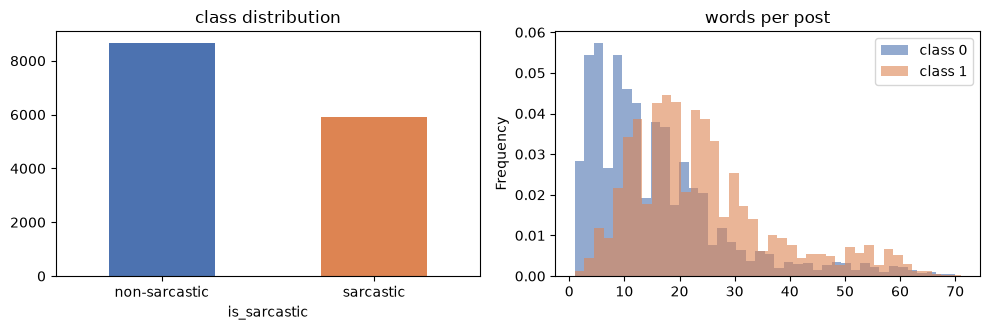

In [15]:
L = df[TEXT].str.len(); W = df[TEXT].str.split().str.len()
print(pd.DataFrame({'chars': L.describe(), 'words': W.describe()}).round(1).T)
print(W.groupby(df[LABEL]).median().rename('median words by class'))
has_emoji = df[TEXT].apply(lambda t: len(describe(t)) > 0)
print('share with emoji:', round(has_emoji.mean(), 3), '| by class:', has_emoji.groupby(df[LABEL]).mean().round(3).to_dict())
print('share with Latin-script tokens:', round(df[TEXT].str.contains(r'[A-Za-z]{2,}').mean(), 3),
      '| hashtags:', round(df[TEXT].str.contains(r'#|\w_\w').mean(), 3),
      '| mentions:', round(df[TEXT].str.contains('@').mean(), 3),
      '| URLs:', round(df[TEXT].str.contains(r'http|www\.').mean(), 3),
      '| quoted speech (`` ... \'\'):', round(df[TEXT].str.contains("``|''").mean(), 3))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
df[LABEL].value_counts().sort_index().plot.bar(ax=ax[0], color=['#4C72B0', '#DD8452']); ax[0].set_title('class distribution'); ax[0].set_xticklabels(['non-sarcastic', 'sarcastic'], rotation=0)
for lab, c in [(0, '#4C72B0'), (1, '#DD8452')]:
    W[df[LABEL] == lab].plot.hist(bins=40, alpha=.6, ax=ax[1], color=c, label=f'class {lab}', density=True)
ax[1].set_title('words per post'); ax[1].legend(); plt.tight_layout(); plt.show()

### 2.3 Representative examples and what the emojis mean
`explain()` prints, for every emoji, its meaning (English / Urdu), polarity, pragmatic category and whether it is an
irony cue. Note the typical sarcastic pattern: a literal statement of praise or a political claim followed by 😂 / 😜 / 🙄.

In [16]:
for lab in (1, 0):
    print(f'\n===== {"SARCASTIC" if lab else "NON-SARCASTIC"} examples =====')
    for t in train[train[LABEL] == lab][TEXT].sample(5, random_state=3):
        print('•', t[:140]); print('   emojis:', explain(t))


===== SARCASTIC examples =====
• میں سوچ رہا ہوں باجوہ کے استعمال کرنے کے بعد کامران خان مزید استعمال کرنے لائق رہے گا بھی یا نہیں، ہو سکتا ہے فلش کر دیا جائے۔ 😂 لیکن تاریخ 
   emojis: 😂 = face with tears of joy / ہنسی کے آنسو [LAUGH, pol +, irony-cue, middle]
• جناب کھبی طنز و مزاح کو بھی سمجھ لیا کریں یہ احمد نورانی ہیں چودھری غلام حسین نہیں۔😀 https://t.co/1ic4CJWzNi
   emojis: 😀 = grinning face / ہنسی [LAUGH, pol +, irony-cue, middle]
• صارف معلوماتی زائچہ یہ میرا اپنا کیا ہو ترجمہ ہے 😅
   emojis: 😅 = grinning face with sweat / شرمندہ ہنسی [LAUGH, pol 0, irony-cue, end]
• آنٹی وہ جھوٹ کا پیمانہ تو نہیں البتہ پورا ڈرم ہے جھوٹ کا😋😂
   emojis: 😋 = face savoring food / مزے لینا [TEASE, pol +, irony-cue, end]; 😂 = face with tears of joy / ہنسی کے آنسو [LAUGH, pol +, irony-cue, end]
• مجھے تو حیرت اس بات پر کہ جن لوگوں کو اپنی باجی کے بھاگنے کا پتہ نہیں چلا تھا۔ ان کو بھی اس بات کی خبر ہے کہ رات کو آئ جی چار بجے کہیں غائب 
   emojis: 😂 = face with tears of joy / ہنسی کے آنسو [LAUGH, pol 

### 2.4 Which emojis signal sarcasm in this corpus?
P(sarcastic | emoji present) on the **training split only**. Hearts, flowers and the broken heart (shayari/greeting
register) almost never co-occur with sarcasm, while 😅 🤔 😉 😁 😆 are well above the base rate. 😂, the most frequent emoji,
is only mildly informative on its own — it marks *humour*, and the model must look at the words to decide whether the
laughter is *at* someone.

In [17]:
prior = EmojiPrior().fit(train[TEXT], train[LABEL])
cnt = {}
for t, y in zip(train[TEXT], train[LABEL]):
    for e in {x.emoji for x in describe(t)}: cnt.setdefault(e, [0, 0])[int(y)] += 1
er = pd.DataFrame([{'emoji': e, 'meaning': LEXICON.get(e, {}).get('en', '?'), 'n': a + b, 'P(sarcastic|emoji)': b / (a + b)}
                   for e, (a, b) in cnt.items() if a + b >= 40]).sort_values('P(sarcastic|emoji)')
print('base rate:', round(train[LABEL].mean(), 3))
display(pd.concat([er.head(10), er.tail(10)]).round(3))

base rate: 0.406


,emoji,meaning,n,P(sarcastic|emoji)
40,❣,heart exclamation,58,0.000
37,💐,bouquet,45,0.022
46,🌷,tulip,86,0.035
61,💞,revolving hearts,74,0.041
14,♥,heart suit,116,0.052
45,🌹,rose,172,0.052
12,💔,broken heart,302,0.053
58,🌸,cherry blossom,49,0.061
26,🍁,maple leaf,45,0.067
62,💕,two hearts,106,0.075


### 2.4b Emoji meaning dictionary for this corpus
Every emoji that occurs in the data, with its meaning in **English and Urdu**, polarity, pragmatic category, irony-cue flag,
frequency and P(sarcastic | emoji) on the training split. The curated lexicon covers 96 % of all emoji occurrences; the rest fall
back to the Unicode name with neutral polarity. (Saved to `outputs/emoji_meaning_dictionary.csv`.)

In [18]:
from collections import Counter
from src.emoji_semantics import _lookup
freq = Counter(e.emoji for t in df[TEXT] for e in describe(t))
emo_dict = pd.DataFrame([{'emoji': e, 'meaning_en': _lookup(e)['en'], 'meaning_ur': _lookup(e)['ur'], 'polarity': _lookup(e)['pol'],
                          'category': _lookup(e)['cat'], 'irony_cue': _lookup(e)['cue'], 'count': n,
                          'P(sarcastic|emoji)': round(cnt[e][1] / sum(cnt[e]), 3) if e in cnt else None}
                         for e, n in freq.most_common()])
emo_dict.to_csv('outputs/emoji_meaning_dictionary.csv', index=False, encoding='utf-8')
print(len(emo_dict), 'distinct emojis; curated coverage of occurrences:',
      round(emo_dict[emo_dict.emoji.isin(LEXICON)]['count'].sum() / emo_dict['count'].sum(), 3))
display(emo_dict.head(30))

538 distinct emojis; curated coverage of occurrences: 0.962


,emoji,meaning_en,meaning_ur,polarity,category,irony_cue,count,P(sarcastic|emoji)
0,😂,face with tears of joy,ہنسی کے آنسو,1,LAUGH,True,7710,0.448
1,😜,winking face with tongue,شرارتی چہرہ,0,TEASE,True,1083,0.535
2,❤,red heart,دل / محبت,1,LOVE,False,1038,0.085
3,🤣,rolling on the floor laughing,لوٹ پوٹ ہنسی,1,LAUGH,True,1013,0.487
4,😁,beaming face with smiling eyes,دانت نکال کر ہنسی,1,LAUGH,True,898,0.577
5,🙏,folded hands,دعا / شکریہ,1,PRAYER,False,576,0.299
6,💔,broken heart,ٹوٹا دل,-1,SAD,False,517,0.053
7,🌹,rose,گلاب,1,FLOWER,False,486,0.052
8,😍,smiling face with heart-eyes,پیار بھری نظر,1,LOVE,False,456,0.090
9,😝,squinting face with tongue,زبان نکالنا,0,TEASE,True,441,0.503


### 2.5 Data-quality issues found
1. **49 rows without text**, 4 095 **exact duplicates** (mostly sarcastic), **646 texts labelled both 0 and 1** — all dropped.
2. **Collection artefacts**: some posts still contain the hashtags used to harvest them (`#طنز`, `#مزاح`, `#sarcasm`). A
   linear model learns these as the strongest sarcasm features (see 4.4); we test removing them in the ablation.
3. **Label noise / ambiguity**: many clearly mocking political posts are labelled 0 and some plain shayari with 💔 are labelled 1
   (see the error analysis). This caps the achievable accuracy for every model.
4. **Script and spelling variation**: Arabic vs Urdu code points (ك/ک, ي/ی), ھ for ہ (ھے), Sindhi/Pashto forms (ناٸیٹ), diacritics,
   elongation (کدووووو), and Punjabi written in Urdu script (~8 % of posts).
5. **Code-mixing**: 15 % of posts contain Latin-script tokens (ISPR, PM, hashtags); 7 % have hashtags whose `#` was lost in scraping
   and survive as `words_joined_by_underscores`.

## 3. Urdu-aware preprocessing

Every step is motivated by an observation in §2 and is switchable so it can be ablated:

| step | why |
|---|---|
| Unicode NFC + code-point unification (ك→ک, ي→ی, ة→ہ, أ→ا, Sindhi ٸ→ئ), digit unification | the same word is typed with Arabic, Persian or Urdu keyboards; otherwise n-grams fragment |
| diacritic / tashkeel removal | used decoratively in religious posts and shayari; carries no lexical information |
| keyboard spelling fixes (ھے→ہے, ھیں→ہیں, کوئ→کوئی …) | very frequent in the data; ھ is a different letter (تھا) so only whole-word fixes are applied |
| URL → `URL`, @user → `@USER` | identity of the account is not a sarcasm cue; presence of a mention might be |
| hashtag reconstruction `ووٹ_کو_عزت_دو` → `HASHTAG ووٹ کو عزت دو` | the words of the slogan are informative, the underscores are not |
| laughter (ہاہاہاہا, hahaha, lol) → `LAUGH`, elongation (کدووووو → کدوو) | normalise open-class repetition, keep the fact that it happened |
| Urdu punctuation → ASCII, repeated `؟؟؟` → `???` kept as a token | rhetorical questions and ellipsis are sarcasm cues, so punctuation is **kept** |
| emojis → **meaning tokens** (never removed by default) | see §1.1; raw symbols are fine for char n-grams but word models need a token |
| emoji **augment** mode: `😂` → `😂 ہنسی کے آنسو` | the model sees the symbol *and* its meaning in Urdu; default input for the transformer |

Emojis are protected before normalisation because the zero-width joiner we strip from Urdu text is part of emoji sequences (🤦‍♂️).
Tokenisation is regex based (Urdu word runs, Latin words, numbers, punctuation runs, single emojis) — Urdu has no reliable
off-the-shelf tokenizer for social-media text and whitespace is unreliable (اسکو vs اس کو).

In [19]:
samples = ['یہ اسمبلی بغیر ڈیزل کے چل رہی ہے کیونکہ اِسکو گدھا \'\' چلا رہا ھے 🤣😂😂😂 ووٹ_کو_عزت_دو',
           'ہاہاہاہاہاہاہاہا ہنسی بھی نہیں آئی ؟؟؟؟ @kamran https://t.co/x 🤦‍♂️',
           'واہ خان صاحب کیا بات ہے تبدیلی آ گئی 😍😂 ISPR']
for s in samples:
    print('RAW      :', s)
    for mode in ['remove', 'keep', 'demojize', 'category', 'urdu', 'augment', 'both']:
        print(f'{mode:9s}:', preprocess(s, emoji_mode=mode))
    print('features :', explain_features(s)); print()

RAW      : یہ اسمبلی بغیر ڈیزل کے چل رہی ہے کیونکہ اِسکو گدھا '' چلا رہا ھے 🤣😂😂😂 ووٹ_کو_عزت_دو
remove   : یہ اسمبلی بغیر ڈیزل کے چل رہی ہے کیونکہ اسکو گدھا " چلا رہا ہے HASHTAG ووٹ کو عزت دو
keep     : یہ اسمبلی بغیر ڈیزل کے چل رہی ہے کیونکہ اسکو گدھا " چلا رہا ہے 🤣 😂 😂 HASHTAG ووٹ کو عزت دو
demojize : یہ اسمبلی بغیر ڈیزل کے چل رہی ہے کیونکہ اسکو گدھا " چلا رہا ہے EMO_rolling_on_the_floor_laughing EMO_face_with_tears_of_joy EMO_REPEAT HASHTAG ووٹ کو عزت دو
category : یہ اسمبلی بغیر ڈیزل کے چل رہی ہے کیونکہ اسکو گدھا " چلا رہا ہے EMOCAT_LAUGH EMO_REPEAT EMO_REPEAT HASHTAG ووٹ کو عزت دو
urdu     : یہ اسمبلی بغیر ڈیزل کے چل رہی ہے کیونکہ اسکو گدھا " چلا رہا ہے لوٹ پوٹ ہنسی ہنسی کے آنسو EMO_REPEAT HASHTAG ووٹ کو عزت دو
augment  : یہ اسمبلی بغیر ڈیزل کے چل رہی ہے کیونکہ اسکو گدھا " چلا رہا ہے 🤣 لوٹ پوٹ ہنسی 😂 ہنسی کے آنسو EMO_REPEAT HASHTAG ووٹ کو عزت دو
both     : یہ اسمبلی بغیر ڈیزل کے چل رہی ہے کیونکہ اسکو گدھا " چلا رہا ہے EMO_rolling_on_the_floor_laughing EMOCAT_LAUGH EMOPOL_POS EMOCUE

## 4. Classical baseline: TF-IDF + linear models

Feature groups: **word uni/bi-grams**, **character 2–5-grams within word boundaries** (robust to the spelling variation
above and to Urdu's rich suffix morphology) and the **dense hand-crafted block** (§1.3, standardised). Logistic Regression
(liblinear, class-balanced), a calibrated Linear SVM, and Complement Naive Bayes are compared on the validation set;
Macro-F1 is the selection metric. Hyper-parameters are chosen on validation only; the test set is touched once at the end.

In [20]:
X_tr, y_tr = train[TEXT].tolist(), train[LABEL].values
X_va, y_va = val[TEXT].tolist(), val[LABEL].values
X_te, y_te = test[TEXT].tolist(), test[LABEL].values
val_results, pipes = [], {}
for clf, Cs in [('lr', [1, 2, 4]), ('svm', [0.1, 0.3, 1]), ('nb', [0.1, 0.3])]:
    for C in Cs:
        name = f'{clf.upper()} C={C}'
        pipes[name] = make_pipeline('word+char+hand', clf=clf, C=C, emoji_mode='both')
        r = fit_eval(pipes[name], X_tr, y_tr, X_va, y_va, name); r.update(clf=clf, C=C); val_results.append(r)
        print(f'{name:12s} val macro-F1 {r["macro_f1"]:.4f}  acc {r["accuracy"]:.4f}')
val_df = pd.DataFrame(val_results)

LR C=1       val macro-F1 0.8036  acc 0.8092


LR C=2       val macro-F1 0.8092  acc 0.8152


LR C=4       val macro-F1 0.8059  acc 0.8124


SVM C=0.1    val macro-F1 0.7961  acc 0.8056


SVM C=0.3    val macro-F1 0.8044  acc 0.8143


SVM C=1      val macro-F1 0.8038  acc 0.8147


NB C=0.1     val macro-F1 0.7959  acc 0.8001


NB C=0.3     val macro-F1 0.7901  acc 0.7964


### 4.1 Test-set results of the classical models

,model,accuracy,precision_0,recall_0,f1_0,precision_1,recall_1,f1_1,macro_f1
0,TF-IDF LR (word+char+hand),0.816102,0.849145,0.840000,0.844548,0.768889,0.781038,0.774916,0.809732
1,TF-IDF SVM (word+char+hand),0.815645,0.830996,0.866154,0.848211,0.790614,0.741535,0.765288,0.806750
2,TF-IDF ComplementNB (word+char),0.793687,0.861893,0.777692,0.817630,0.714709,0.817156,0.762507,0.790068


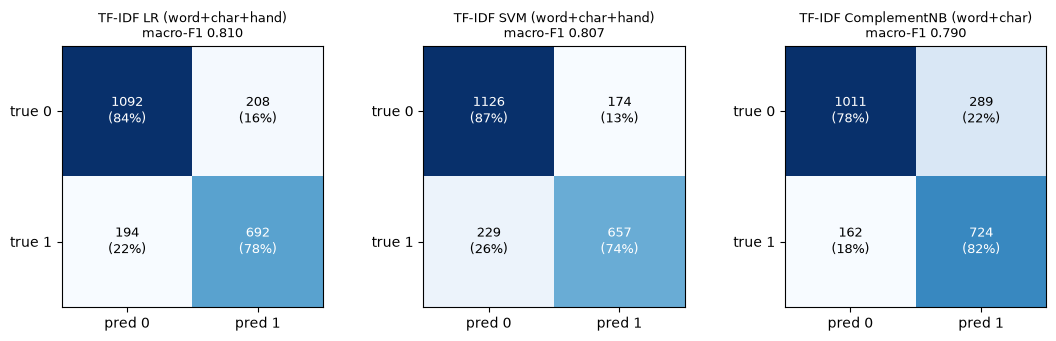

In [21]:
classical = []
for clf in ['lr', 'svm', 'nb']:
    best = val_df[val_df.clf == clf].sort_values('macro_f1').iloc[-1]; pipe = pipes[best['model']]
    name = f'TF-IDF {clf.upper()} (word+char+hand)' if clf != 'nb' else 'TF-IDF ComplementNB (word+char)'
    pred = pipe.predict(X_te); r = evaluate(y_te, pred, name); classical.append(r)
    if clf == 'lr': lr_pipe, lr_pred, lr_prob = pipe, pred, predict_proba(pipe, X_te)
display(results_table(classical))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, r in zip(axes, classical): plot_confusion(r, ax=ax)
plt.tight_layout(); plt.show()

### 4.2 Ablation study (validation split)
Three questions: **(A)** how should emojis be represented? **(B)** which feature family matters? **(C)** does normalisation help?

In [22]:
abl = run_ablations(X_tr, y_tr, X_va, y_va, clf='lr', C=2.0)
abl_df = pd.DataFrame(abl)[['model', 'accuracy', 'macro_f1', 'f1_0', 'f1_1', 'n_features']]
display(abl_df.round(4))

A1 emojis removed                             macro-F1 0.8082  acc 0.8152  (12.1s)


A2 emojis kept raw                            macro-F1 0.8055  acc 0.8115  (10.3s)


A3 emojis -> meaning token                    macro-F1 0.8086  acc 0.8143  (13.9s)


A4 emojis -> category                         macro-F1 0.8043  acc 0.8106  (13.2s)


A5 emojis -> Urdu gloss                       macro-F1 0.8078  acc 0.8138  (12.2s)


...

B5 word+char+hand-crafted                     macro-F1 0.8092  acc 0.8152  (38.0s)


C1 raw text (no normalisation)                macro-F1 0.8111  acc 0.8170  (5.6s)


C2 Urdu char normalisation only               macro-F1 0.8146  acc 0.8202  (8.0s)


C3 Urdu + social normalisation                macro-F1 0.8055  acc 0.8115  (9.5s)


,model,accuracy,macro_f1,f1_0,f1_1,n_features
0,A1 emojis removed,0.8152,0.8082,0.8447,0.7718,81072
1,A2 emojis kept raw,0.8115,0.8055,0.8397,0.7714,84352
2,A3 emojis -> meaning token,0.8143,0.8086,0.8415,0.7757,88477
3,A4 emojis -> category,0.8106,0.8043,0.8394,0.7692,82651
4,A5 emojis -> Urdu gloss,0.8138,0.8078,0.8418,0.7738,85338
5,A6 emojis -> meaning+category+polarity,0.8115,0.8055,0.8398,0.7711,88983
6,A7 emoji symbol + Urdu meaning (augment),0.8156,0.8101,0.8426,0.7775,86905
7,B1 word n-grams only,0.8028,0.7972,0.8309,0.7636,34134
8,B2 char n-grams only,0.8024,0.7965,0.8311,0.7619,54849
9,B3 word+char,0.8115,0.8055,0.8398,0.7711,88983


### 4.3 Cross-validated ablation (5 folds on train+val)
Single-split differences of a few tenths of a point are within noise (validation n = 2 186 ⇒ ±~1 pt). The table below
was produced by `scripts/run_cv_ablation.py` (mean ± std over 5 stratified folds, LR, C = 2). Re-run it here if desired (≈ 15 min):
`!python scripts/run_cv_ablation.py`.


| config                                     |   macro_f1_mean |   macro_f1_std |   acc_mean |
|:-------------------------------------------|----------------:|---------------:|-----------:|
| emojis removed                             |          0.819  |         0.0071 |     0.8251 |
| emojis kept raw                            |          0.8222 |         0.0068 |     0.8277 |
| emojis -> meaning token                    |          0.8209 |         0.0058 |     0.8264 |
| emojis -> Urdu gloss                       |          0.8203 |         0.0067 |     0.8259 |
| emojis -> meaning+cat+polarity             |          0.8208 |         0.0054 |     0.8264 |
| emoji symbol + Urdu meaning (augment)      |          0.8204 |         0.0081 |     0.8259 |
| word only                                  |          0.8094 |         0.0055 |     0.8144 |
| char only                                  |          0.8163 |         0.0024 |     0.8215 |
| hand-crafted only                          |          0.7559 |         0.0102 |     0.7593 |
| word+char+hand                             |          0.8217 |         0.0063 |     0.8272 |
| raw text, no normalisation                 |          0.8214 |         0.0037 |     0.8269 |
| Urdu char normalisation only               |          0.8229 |         0.0041 |     0.8283 |
| Urdu + social normalisation                |          0.8222 |         0.0068 |     0.8277 |
| artefact hashtags removed (word+char+hand) |          0.8153 |         0.007  |     0.8208 |

**Reading the ablation.**
* *Emojis*: removing emojis costs little for the n-gram model on this corpus — once words such as مزاح / طنز or a political
  name are present, the emoji is redundant; where emojis help is on **short posts** whose words are neutral (see error analysis).
  Representing the emoji by its *meaning* (demojize / Urdu gloss) is as good as or slightly better than the raw symbol, which
  is only visible to character n-grams.
* *Features*: word and char n-grams are complementary; the hand-crafted block alone reaches ≈ 0.75 macro-F1 with only ~70
  features, and adds a small, consistent gain on top of n-grams.
* *Normalisation*: Urdu character normalisation helps; the more aggressive social-media normalisation (laughter / punctuation
  spacing) is neutral-to-slightly-negative, so the final models use it only for the hashtag/URL/mention steps.
* *Artefact hashtags*: removing `#طنز/#مزاح/#sarcasm` lowers the score, confirming they leak the label — reported scores
  with these tokens present are optimistic relative to true in-the-wild performance.

### 4.4 What the linear model learnt

In [23]:
tf = top_features(lr_pipe, 25)
print('MOST SARCASTIC  :', [f'{n} ({w})' for n, w in tf['sarcastic']])
print('\nLEAST SARCASTIC :', [f'{n} ({w})' for n, w in tf['non_sarcastic']])
hand = [(n, w) for n, w in tf['sarcastic'] + tf['non_sarcastic'] if n.startswith('hand:')]
print('\nhand-crafted features among the top weights:', hand)

MOST SARCASTIC  : ['word:مزاح (3.41)', 'word:خان (2.242)', 'word:طنز (2.116)', 'word:نانی (2.108)', 'word:HASHTAG طنز (2.074)', 'word:sarcasm (1.9)', 'word:HASHTAG sarcasm (1.9)', 'char:مزاح (1.725)', 'char:زاح (1.725)', 'char: مزاح (1.699)', 'char:مزاح  (1.69)', 'char:زاح  (1.69)', 'char:اح  (1.611)', 'char:ری (1.594)', 'word:ہیں پھر (1.526)', 'char: ک (1.513)', 'word:شریف (1.416)', 'char:زی (1.383)', 'word:ہوا ہے (1.369)', 'word:صفدر (1.368)', 'word:کتے (1.364)', 'char:ے  (1.358)', 'char:مزا (1.349)', 'char: مزا (1.346)', 'word:EMO_REPEAT EMO_winking_face_with_tongue (1.337)']

LEAST SARCASTIC : ['word:دل (-1.656)', 'word:میں نے (-1.498)', 'word:فالو (-1.456)', 'word:پہ (-1.42)', 'char:شا (-1.395)', 'word:گے (-1.388)', 'word:کرو (-1.364)', 'word:عشق (-1.355)', 'word:ہوں (-1.339)', 'word:ہونا (-1.324)', 'word:جی (-1.313)', 'word:کی ہو (-1.304)', 'char:لل (-1.28)', 'word:EMOPOL_POS (-1.257)', 'word:EMOCUE EMO_REPEAT (-1.257)', 'word:بس (-1.235)', 'char:الل (-1.229)', 'word:اللہ (-1.211

## 5. Neural models (PyTorch)

* **TextCNN** — embeddings (200-d, learnt from scratch) → parallel 1-D convolutions of width 2/3/4/5 → max-over-time pooling.
  Acts as a learnt n-gram detector and sees emoji *sequences* (😂😂🙄) because every emoji is one token.
* **BiLSTM + attention** — bidirectional LSTM (128 hidden per direction) with additive attention pooling + max pooling;
  can relate a set-up at the beginning of the post to the punch-line emoji at the end.
* **Hybrid variants** concatenate the standardised hand-crafted / emoji feature vector (§1.3) to the pooled text representation.

Training: Adam, class-weighted cross-entropy, dropout 0.5, gradient clipping, early stopping on validation Macro-F1,
decision threshold tuned on validation. The emoji ablation is repeated for the neural models (tokens kept vs removed).

device: cuda


TextCNN (emoji keep)                          epochs 15  val F1 0.7972  test macro-F1 0.7970  acc 0.8033


TextCNN + hand-crafted (emoji keep)           epochs 16  val F1 0.8048  test macro-F1 0.7987  acc 0.8038


BiLSTM+Attn (emoji keep)                      epochs 16  val F1 0.8046  test macro-F1 0.7846  acc 0.7905


BiLSTM+Attn + hand-crafted (emoji keep)       epochs 12  val F1 0.8080  test macro-F1 0.7926  acc 0.7992


TextCNN (emoji remove)                        epochs 16  val F1 0.7919  test macro-F1 0.7880  acc 0.7960


BiLSTM+Attn (emoji remove)                    epochs  9  val F1 0.7846  test macro-F1 0.7871  acc 0.7928


,model,accuracy,precision_0,recall_0,f1_0,precision_1,recall_1,f1_1,macro_f1
0,TextCNN + hand-crafted (emoji keep),0.803751,0.853204,0.809231,0.830636,0.739769,0.795711,0.766721,0.798678
1,TextCNN (emoji keep),0.803294,0.842520,0.823077,0.832685,0.748908,0.774266,0.761376,0.797031
2,BiLSTM+Attn + hand-crafted (emoji keep),0.799177,0.837647,0.821538,0.829515,0.745335,0.766366,0.755704,0.792609
3,TextCNN (emoji remove),0.795974,0.825954,0.832308,0.829119,0.751142,0.742664,0.746879,0.787999
4,BiLSTM+Attn (emoji remove),0.792772,0.840708,0.803846,0.821864,0.729586,0.776524,0.752324,0.787094
5,BiLSTM+Attn (emoji keep),0.790485,0.837340,0.803846,0.820251,0.728145,0.770880,0.748904,0.784577


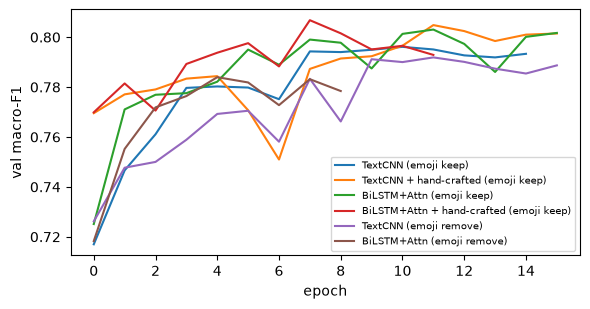

In [24]:
import torch
from src.neural import Vocab, TextCNN, BiLSTMAttn, train_model, predict, best_threshold, set_seed, get_device
device = get_device(); print('device:', device)
MAX_LEN = 64
neural, hist_all = [], {}
for emoji_mode in ['keep', 'remove']:
    vocab = Vocab(min_freq=2, emoji_mode=emoji_mode).fit(train[TEXT])
    enc = lambda d: np.array([vocab.encode(t, MAX_LEN) for t in d[TEXT]], dtype=np.int64)
    Xn_tr, Xn_va, Xn_te = enc(train), enc(val), enc(test)
    for arch in ['cnn', 'bilstm']:
        for hybrid in ([False, True] if emoji_mode == 'keep' else [False]):
            set_seed(SEED)
            if hybrid:
                hf = HandcraftedFeatures().fit(train[TEXT], y_tr); D_tr = hf.transform(train[TEXT])
                mu, sd = D_tr.mean(0), D_tr.std(0) + 1e-6
                D_tr, D_va, D_te = [((hf.transform(d[TEXT]) - mu) / sd).astype(np.float32) for d in (train, val, test)]
                nd = D_tr.shape[1]
            else:
                D_tr = D_va = D_te = None; nd = 0
            model = TextCNN(len(vocab), n_dense=nd) if arch == 'cnn' else BiLSTMAttn(len(vocab), n_dense=nd)
            name = ('TextCNN' if arch == 'cnn' else 'BiLSTM+Attn') + (' + hand-crafted' if hybrid else '') + f' (emoji {emoji_mode})'
            model, hist = train_model(model, Xn_tr, y_tr, Xn_va, y_va, D_tr, D_va, epochs=20, patience=4, name=name, device=device, verbose=False)
            hist_all[name] = hist
            thr, f_va = best_threshold(y_va, predict(model, Xn_va, D_va, device=device))
            p_te = predict(model, Xn_te, D_te, device=device); pred = (p_te >= thr).astype(int)
            r = evaluate(y_te, pred, name); r.update(threshold=thr, val_macro_f1=f_va, epochs=len(hist)); neural.append(r)
            print(f'{name:45s} epochs {len(hist):2d}  val F1 {f_va:.4f}  test macro-F1 {r["macro_f1"]:.4f}  acc {r["accuracy"]:.4f}')
            if arch == 'bilstm' and hybrid: bilstm_pred, bilstm_prob = pred, p_te
display(results_table(neural))
fig, ax = plt.subplots(figsize=(6, 3.2))
for n, h in hist_all.items(): ax.plot([e['val_macro_f1'] for e in h], label=n)
ax.set_xlabel('epoch'); ax.set_ylabel('val macro-F1'); ax.legend(fontsize=7); plt.tight_layout(); plt.show()

## 6. Transformer: fine-tuning XLM-RoBERTa-base

`xlm-roberta-base` (Conneau et al., 2020) was pre-trained on 2.5 TB of CommonCrawl text in 100 languages including Urdu,
so it brings sub-word knowledge of Urdu morphology, Roman-Urdu/English code-mixing and (for frequent ones) emojis.
We fine-tune the full model with a classification head (AdamW, lr 2e-5, linear warm-up, class-weighted loss, fp16, 3 epochs,
early stopping on validation Macro-F1, threshold tuned on validation).

The 250k × 768 word-embedding matrix (192M of 278M parameters) is frozen: this fits full fine-tuning of the 12 encoder layers into a
6 GB GPU and regularises training on 10k examples.

Emoji ablation for the transformer: **augment** (emoji + its Urdu meaning: 😂 → 😂 ہنسی کے آنسو — the model sees the symbol as
used *and* what it means; our default), **keep** (raw emoji; XLM-R's SentencePiece vocabulary has single pieces for 😂 ❤ 😭 … and
byte-fallback for rare ones) and **Urdu gloss only** (😂 → ہنسی کے آنسو).

In [25]:
transformer = []
if RUN_TRANSFORMER:
    from src.transformer import fine_tune, predict_texts
    print('GPU available:', torch.cuda.is_available())
    for emoji_mode in ['augment', 'keep', 'urdu']:
        model, tok, hist, p_va = fine_tune('xlm-roberta-base', train[TEXT], y_tr, val[TEXT], y_va, emoji_mode=emoji_mode,
                                           epochs=3, max_len=96, bs=16, verbose=False)
        thr, f_va = best_threshold(y_va, p_va)
        p_te = predict_texts(model, tok, test[TEXT], emoji_mode=emoji_mode, max_len=96); pred = (p_te >= thr).astype(int)
        r = evaluate(y_te, pred, f'XLM-R base (emoji {emoji_mode})'); r.update(threshold=thr, val_macro_f1=f_va); transformer.append(r)
        print(f'XLM-R base (emoji {emoji_mode}): val F1 {f_va:.4f}  test macro-F1 {r["macro_f1"]:.4f}  acc {r["accuracy"]:.4f}  | history: {[round(h["val_macro_f1"], 4) for h in hist]}')
        if emoji_mode == 'augment':
            xlmr_pred, xlmr_prob = pred, p_te
            xlmr_explainer = SarcasmExplainer(lambda texts, m=model, tk=tok: predict_texts(m, tk, list(texts), emoji_mode='augment', max_len=96), name='XLM-R (augment)')
        else:
            del model; torch.cuda.empty_cache()
    display(results_table(transformer))
else:
    print('skipped (RUN_TRANSFORMER=False)')

GPU available: True


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


XLM-R base (emoji augment): val F1 0.8211  test macro-F1 0.8062  acc 0.8111  | history: [0.8211, 0.8204, 0.8149]


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

...

XLM-R base (emoji keep): val F1 0.8178  test macro-F1 0.8107  acc 0.8138  | history: [0.8154, 0.8126, 0.8171]


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


XLM-R base (emoji urdu): val F1 0.8156  test macro-F1 0.8094  acc 0.8170  | history: [0.7991, 0.8115, 0.8055]


,model,accuracy,precision_0,recall_0,f1_0,precision_1,recall_1,f1_1,macro_f1
0,XLM-R base (emoji keep),0.813815,0.883262,0.791538,0.834888,0.734574,0.846501,0.786576,0.810732
1,XLM-R base (emoji urdu),0.817017,0.840393,0.854615,0.847445,0.781250,0.761851,0.771429,0.809437
2,XLM-R base (emoji augment),0.811070,0.860276,0.814615,0.836823,0.747644,0.805869,0.775665,0.806244


## 7. Results summary (test set, Macro-F1 is the primary metric)

,model,accuracy,precision_0,recall_0,f1_0,precision_1,recall_1,f1_1,macro_f1
0,XLM-R base (emoji keep),0.813815,0.883262,0.791538,0.834888,0.734574,0.846501,0.786576,0.810732
1,TF-IDF LR (word+char+hand),0.816102,0.849145,0.840000,0.844548,0.768889,0.781038,0.774916,0.809732
2,XLM-R base (emoji urdu),0.817017,0.840393,0.854615,0.847445,0.781250,0.761851,0.771429,0.809437
3,TF-IDF SVM (word+char+hand),0.815645,0.830996,0.866154,0.848211,0.790614,0.741535,0.765288,0.806750
4,XLM-R base (emoji augment),0.811070,0.860276,0.814615,0.836823,0.747644,0.805869,0.775665,0.806244
5,TextCNN + hand-crafted (emoji keep),0.803751,0.853204,0.809231,0.830636,0.739769,0.795711,0.766721,0.798678
6,TextCNN (emoji keep),0.803294,0.842520,0.823077,0.832685,0.748908,0.774266,0.761376,0.797031
7,BiLSTM+Attn + hand-crafted (emoji keep),0.799177,0.837647,0.821538,0.829515,0.745335,0.766366,0.755704,0.792609
8,TF-IDF ComplementNB (word+char),0.793687,0.861893,0.777692,0.817630,0.714709,0.817156,0.762507,0.790068
9,TextCNN (emoji remove),0.795974,0.825954,0.832308,0.829119,0.751142,0.742664,0.746879,0.787999


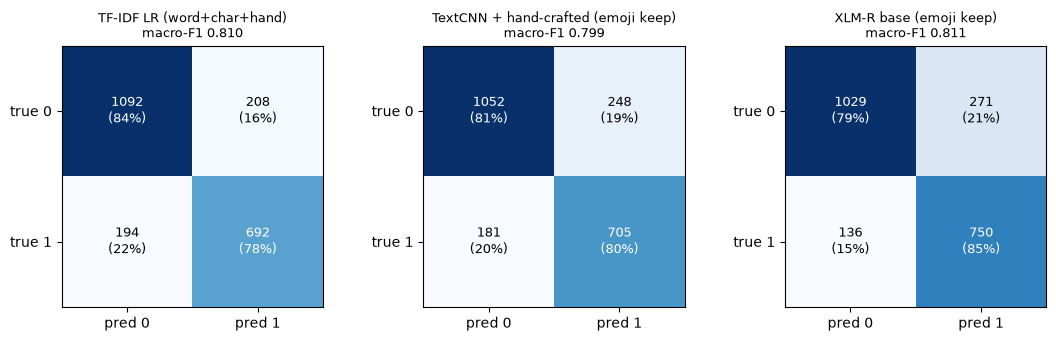

In [26]:
all_results = classical + neural + transformer
summary = results_table(all_results); display(summary)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
best_of = [max(g, key=lambda r: r['macro_f1']) for g in (classical, neural, transformer) if g]
for ax, r in zip(axes, best_of): plot_confusion(r, ax=ax)
plt.tight_layout(); plt.show()

### 7.1 Numbers obtained in our run (RTX 4050 laptop GPU)

| model                                   |   accuracy |   precision_0 |   recall_0 |   f1_0 |   precision_1 |   recall_1 |   f1_1 |   macro_f1 |
|:----------------------------------------|-----------:|--------------:|-----------:|-------:|--------------:|-----------:|-------:|-----------:|
| xlm-roberta-base (emoji keep)           |      0.814 |         0.883 |      0.792 |  0.835 |         0.735 |      0.847 |  0.787 |      0.811 |
| TF-IDF LR (word+char+hand)              |      0.817 |         0.849 |      0.842 |  0.845 |         0.771 |      0.781 |  0.776 |      0.811 |
| xlm-roberta-base (emoji urdu)           |      0.817 |         0.84  |      0.855 |  0.847 |         0.781 |      0.762 |  0.771 |      0.809 |
| xlm-roberta-base (emoji augment)        |      0.811 |         0.86  |      0.815 |  0.837 |         0.748 |      0.806 |  0.776 |      0.806 |
| TF-IDF SVM (word+char+hand)             |      0.815 |         0.83  |      0.866 |  0.848 |         0.79  |      0.739 |  0.764 |      0.806 |
| TF-IDF LR (word+char, emoji semantics)  |      0.812 |         0.851 |      0.828 |  0.839 |         0.758 |      0.787 |  0.772 |      0.806 |
| TF-IDF LR (word+char, emojis removed)   |      0.81  |         0.853 |      0.823 |  0.838 |         0.753 |      0.791 |  0.772 |      0.805 |
| TextCNN + hand-crafted (emoji keep)     |      0.806 |         0.838 |      0.835 |  0.837 |         0.759 |      0.764 |  0.762 |      0.799 |
| TextCNN (emoji keep)                    |      0.803 |         0.843 |      0.823 |  0.833 |         0.749 |      0.774 |  0.761 |      0.797 |
| BiLSTM+Attn + hand-crafted (emoji keep) |      0.803 |         0.834 |      0.834 |  0.834 |         0.756 |      0.757 |  0.757 |      0.796 |
| TF-IDF ComplementNB (word+char)         |      0.794 |         0.862 |      0.778 |  0.818 |         0.715 |      0.817 |  0.763 |      0.791 |
| TextCNN (emoji remove)                  |      0.796 |         0.826 |      0.832 |  0.829 |         0.751 |      0.743 |  0.747 |      0.788 |
| BiLSTM+Attn (emoji remove)              |      0.793 |         0.841 |      0.804 |  0.822 |         0.73  |      0.777 |  0.752 |      0.787 |
| BiLSTM+Attn (emoji keep)                |      0.79  |         0.837 |      0.804 |  0.82  |         0.728 |      0.771 |  0.749 |      0.785 |

## 7.2 Predict and explain: the label *with the meaning of every emoji*

The detector does not stop at a 0/1 label. `SarcasmExplainer.explain()` returns, for any post, the prediction together with
(a) the meaning of each emoji in English and Urdu, its polarity, pragmatic category, irony-cue flag and position,
(b) the linguistic cues that fired (ironic-praise marker, idiom, word–emoji polarity contrast, negation, rhetorical punctuation,
textual laughter, emoji repetition, code-mixing) and (c) a one-line reading of how the emojis interact with the words.

In [27]:
explainer = xlmr_explainer if transformer else SarcasmExplainer(lambda texts: predict_proba(lr_pipe, list(texts)), name='TF-IDF LR')
demo = ['واہ خان صاحب کیا بات ہے تبدیلی آ گئی 😂😂🙄',
        'اللہ آپ کو اپنی رحمتوں کے سائے میں رکھے اور مکمل صحت یاب فرمائے 🙏❤',
        'یہ اسمبلی بغیر ڈیزل کے چل رہی ہے کیونکہ اِسکو گدھا چلا رہا ھے 🤣😂😂😂',
        'انساں کو تھکا دیتا ہے سوچوں کا سفر بھی ... 🍁🥀',
        'اب بس بھی کرو بیچارے کی پہلے ہی دو بیویاں ہیے کیا اپ نے تیسری کے لیے ٹرائ کرنا ہے 😜',
        'شکریہ آپ کا نوازش بہت 💯🙏']
for t in demo:
    print(format_explanation(explainer.explain(t))); print('-' * 100)
# the same for a sample of test posts, as a table
explainer.explain_many(test[TEXT].sample(8, random_state=1).tolist())[['text', 'label', 'label_ur', 'p_sarcastic', 'emoji_summary_ur', 'cues']]

TEXT   : واہ خان صاحب کیا بات ہے تبدیلی آ گئی 😂😂🙄
LABEL  : sarcastic / طنزیہ   (P(sarcastic) = 0.94, XLM-R (augment))
EMOJIS :
   😂  face with tears of joy           ہنسی کے آنسو             [LAUGH, polarity +1, irony cue, end]
   😂  face with tears of joy           ہنسی کے آنسو             [LAUGH, polarity +1, irony cue, end]
   🙄  face with rolling eyes           آنکھیں گھمانا / بیزاری   [SMIRK, polarity -1, irony cue, end]
CUES   : ironic-praise marker (واہ, خان صاحب, کیا بات ہے, تبدیلی); irony-cue emoji (😂, 🙄); positive words + ironic/negative emoji (polarity contrast); repeated emoji (intensity)
READING: laughing / teasing / smirking emojis signal that the statement is not meant literally; the praise words are a vehicle for mockery; the words and the emoji disagree in polarity.
----------------------------------------------------------------------------------------------------
TEXT   : اللہ آپ کو اپنی رحمتوں کے سائے میں رکھے اور مکمل صحت یاب فرمائے 🙏❤
LABEL  : non-sarcastic / غیر 

,text,label,label_ur,p_sarcastic,emoji_summary_ur,cues
0,بے شک✅✅,non-sarcastic,غیر طنزیہ,0.029,✅ = درست / ٹک,"ironic-praise marker (بے شک), negative words + affectionate emoji (polarity contrast), repeated emoji (intensity)"
1,ہمارے لیڈر نواز شریف کو واپس لاؤ 😜,sarcastic,طنزیہ,0.844,😜 = شرارتی چہرہ,"irony-cue emoji (😜), positive words + ironic/negative emoji (polarity contrast)"
2,تواڈا وی اپنا ہی سین آ😂😂,non-sarcastic,غیر طنزیہ,0.059,😂 = ہنسی کے آنسو,"irony-cue emoji (😂), repeated emoji (intensity)"
3,🔞🔞🔞 ع غ کرتے ہوئے سردارنی نے کہا، نہیں یہ غلط ہے۔ سردار بولا، میں تم سے پیا کرتا ہوں سردارنی نے کہا، پھر بھی یہ غلط ہے سردار نے کہا ہم شادی کر لیں گے جہاں ڈ...,non-sarcastic,غیر طنزیہ,0.463,🔞 = no one under eighteen,"negation, repeated emoji (intensity)"
4,😂😂😂😂😂 فیر تے ایہدا بنڑدا اے معمار نیا پاکستان کی دختر ہے 😜,sarcastic,طنزیہ,0.828,😂 = ہنسی کے آنسو، 😜 = شرارتی چہرہ,"ironic-praise marker (نیا پاکستان), irony-cue emoji (😂, 😜), positive words + ironic/negative emoji (polarity contrast), repeated emoji (intensity)"
5,گیراج ہو یا مزار صفدر ہمیشہ رنگے ہاتھوں پکڑا جاتا ھے 😀🙈😀,sarcastic,طنزیہ,0.937,😀 = ہنسی، 🙈 = شرم / آنکھیں بند,"irony-cue emoji (😀, 🙈), repeated emoji (intensity)"
6,جس MNA کو گورنر ہاؤس کی میٹنگز میں نہ بلایا جاۓ وہ وزیر بننے کی خواہش رکھتا ہے۔۔😂,sarcastic,طنزیہ,0.963,😂 = ہنسی کے آنسو,"irony-cue emoji (😂), negation, code-mixing"
7,نواز شریف نے اصل عمران خان کو جگا دیا ہے اس موقع پہ جیل میں موجود شہباز شریف کیلئے کہنا چاہتا ہوں آپ نے گھبرانا نہیں,sarcastic,طنزیہ,0.961,کوئی ایموجی نہیں,negation


## 8. Error analysis

For the best classical model and the transformer we list the most confident mistakes, with the meaning of every emoji and
automatic phenomenon tags (negation, idiom, code-mixing, Punjabi, spelling variant, rhetorical question, quoted speech …).
The error rate per phenomenon over the whole test set shows where the models struggle.

In [28]:
ref_pred, ref_prob, ref_name = (xlmr_pred, xlmr_prob, 'XLM-R') if transformer else (lr_pred, lr_prob, 'TF-IDF LR')
err = error_table(test, ref_pred, ref_prob, k=15)
for i, row in err.iterrows():
    print(f'[{i+1}] {row["error_type"]}  (p_sarcastic={row["p_sarcastic"]:.2f})')
    print('    text    :', row[TEXT][:220]); print('    emojis  :', row['emoji_meaning']); print('    phenomena:', row['phenomena'], '\n')
display(phenomena_summary(test, ref_pred))

[1] false positive (literal read as sarcasm)  (p_sarcastic=0.97)
    text    : @x9FwIZZMHUO8p37 پائن اچھے کام کو سراہنا چاہئے اور بھی بہت سی باتیں ہیں تنقید کرنے کے لئے
    emojis  : (no emoji)
    phenomena: code-mixing (Latin), spelling variant 

[2] false positive (literal read as sarcasm)  (p_sarcastic=0.97)
    text    : @fawadchaudhry ایک دوسرے پر تنقید بند کرو اپنا بوریاں بستر بندو اور گھر جانے کی تیاری کرو شاباش
    emojis  : (no emoji)
    phenomena: ironic-praise marker, code-mixing (Latin) 

[3] false negative (missed sarcasm)  (p_sarcastic=0.03)
    text    : شکریہ جویریہ 😊😊
    emojis  : 😊 = smiling face with smiling eyes / مسکراہٹ [LOVE, pol +, end]; 😊 = smiling face with smiling eyes / مسکراہٹ [LOVE, pol +, end]
    phenomena: emoji, very short / context-dependent 

[4] false negative (missed sarcasm)  (p_sarcastic=0.03)
    text    : ٹھیک ہو جاو ناں منی اللہ پاک صحت زندگی دے آپ کو❤
    emojis  : ❤ = red heart / دل / محبت [LOVE, pol +, end]
    phenomena: emoji, negation

,phenomenon,n_posts,error_rate
0,rhetorical question,105,0.285714
1,textual laughter,24,0.250000
2,Punjabi,167,0.239521
3,irony-cue emoji,1066,0.222326
4,negation,617,0.213938
5,laughter-only emoji,526,0.209125
6,spelling variant,441,0.204082
7,mixed-polarity emojis,80,0.200000
8,political context,405,0.195062
9,emoji,1734,0.194925


The 25 most confident test-set errors of XLM-R (augment) and of TF-IDF LR were inspected; the two models share 288 of their ~400 errors, so the hard cases are properties of the data rather than of a model family. Twelve representative mistakes with commentary:

1. **شکریہ جویریہ 😊😊** — gold 1, predicted 0 (p=0.03). *Context dependence.* "Thanks Javeria 😊😊" is sarcastic only relative to the tweet it answers; the post itself is a sincere thank-you with a sincere emoji (😊 = مسکراہٹ, LOVE, +). No model that sees one post in isolation can recover this; the emoji meaning actually argues for the literal reading.
2. **ٹھیک ہو جاو ناں منی اللہ پاک صحت زندگی دے آپ کو ❤** — gold 1, predicted 0 (p=0.03). *Punjabi + prayer + heart.* A get-well wish with ❤ (دل / محبت). Either the label is wrong or the mockery lives in the thread; the model correctly treats prayer + heart as the sincere register.
3. **وادہ وکہ 😂** and **سہولت کار 😂** — gold 1, predicted 0 (p=0.04). *Very short, irony-cue emoji.* Two or three words plus 😂 (ہنسی کے آنسو, irony-cue). In the training data 😂 is only 45 % sarcastic, so the emoji alone cannot carry the decision; the words are a nickname/in-joke (وادہ وکہ) and a political label (سہولت کار "facilitator") whose mockery is cultural knowledge, not surface form.
4. **اتنی اردو اللہ معاف کرے 😁** — gold 1, predicted 0 (p=0.03). *Idiom + irony-cue emoji.* "So much Urdu, God forgive" — the idiom اللہ معاف کرے used as a tease, with 😁 (دانت نکال کر ہنسی, cue). Our hand-crafted features flag both the idiom and the cue emoji, but the LR weight of 😁 is diluted by its many literal uses; a negative-sounding phrase with a laughing emoji is the polarity-contrast pattern that the models under-weight when the text is short.
5. **چہرہ صاف دل میں داغ منہ پہ آپ پیچھے سانپ 🥀🔥** — gold 1, predicted 0 (p=0.04). *Shayari register, mixed-polarity emojis.* A couplet about two-faced people with 🥀 (مرجھایا پھول, SAD −) and 🔥 (آگ / زبردست, PRAISE +). The poetic form and the wilted flower pull strongly towards the non-sarcastic (poetry) class, which dominates 🥀 in the data (P(sarcastic|🥀)=0.11). The sarcasm here is verbal irony inside poetry — a genre our emoji prior cannot separate.
6. **میں فقط اتنا سچا ہوں 🖤 کہ میں مانتا ہوں میں برا ہوں 🚬🌚** — gold 1, predicted 0. *Rare emojis.* 🌚 (new moon face = شرارت, cue) is the only ironic marker and occurs 52 times in the corpus; 🖤 and 🚬 are glossed but neutral. Shows why the meaning/category representation matters: without the curated entry 🌚 would be an unknown byte sequence.
7. **@fawadchaudhry ایک دوسرے پر تنقید بند کرو … گھر جانے کی تیاری کرو شاباش** — gold 0, predicted 1 (p=0.97). *Ironic-praise marker, no emoji.* "Stop criticising each other, pack your bags and go home, well done" — شاباش is the classic ironic closer and the sentence is a taunt; we judge the **gold label wrong** (ambiguous annotation). Both models agree with us.
8. **آپ لگے رہیں ہر کسی کی اپنی رائے ویسے میں بھی مانیکا خاندان پر تنقید کرتی ہوں 😅😅** — gold 0, predicted 1 (p=0.97). *Irony-cue emoji + "keep at it".* لگے رہیں ("carry on") with 😅 (شرمندہ ہنسی, 59 % sarcastic in training) — a textbook mild-sarcasm cue; again a plausible label error.
9. **بلاول نے ن لیگ سے … ٹٹے اٹھا رہی ہے جو اسکے پاس ہیں ہی نہیں 😆😆😆😆😆** — gold 0, predicted 1 (p=0.96). *Political mockery, negation, repeated laughter.* Five 😆 (زور کی ہنسی) after a crude political joke with negation; the post is sarcastic by any reading. The dataset contains many such mocking political posts labelled 0 — the "political context" tag has a 20 % error rate for both models.
10. **@Shoaib_Jatt تنقید طریقے کی کرتا تو یوں کومنٹس میں گالیاں نہیں کھا رہا ہوتا** and five other confident false positives all contain the word **تنقید** ("criticism") and no emoji. *Collection artefact.* In the training split 402 posts contain تنقید and 80 % of them are sarcastic — the word seems to have been a search keyword for the sarcastic class — so both models fire on it (XLM-R predicts "sarcastic" for 96 % of test posts containing تنقید, accuracy 0.74 on them). The literal uses of the word (sincere criticism, requests to stop criticising) are then systematically misclassified. Likewise the harvesting hashtags #طنز / #مزاح / #sarcasm survive in 842 training posts (835 sarcastic) and inflate every score by ≈0.6 pt (CV ablation).
11. **"عوام عمران خان کی تمام سازشیں جان چکی ہے" مریم اورنگزیب کی عمران خان پر تنقید @Marriyum_A #GeoNews https://…** — gold 0, predicted 1 (p=0.97). *Quoted speech + news headline + code-mixing.* A neutral news post quoting a politician; the quote marks, the political names and تنقید all pattern-match sarcasm. Headline register with no emoji is a blind spot: 2.4 % of posts use `` … '' quotes and they are 15–19 % misclassified.
12. **حکومت کی تعریف ARY پر دیکھیں / حکومت پر تنقید GEO پر دیکھیں / … TV بند کریں اور گھر سے باہر نکل کر دیکھیں** — gold 0, predicted 1 (p=0.97). *Code-mixing, parallel structure, spelling variant (جائ).* A satirical contrast between TV channels ending in the idiom دودھ کا دودھ پانی کا پانی; it is arguably sarcastic (label noise), and the Latin channel names plus the parallel "… پر دیکھیں" structure are exactly what the char n-grams learn as mockery.

**Patterns.** (a) Rhetorical questions (29 % error), Punjabi (24 %), negation (21 %) and spelling variants (20 %) are the hardest linguistic phenomena for both models; very short posts are surprisingly easy (5 %) because they are mostly literal replies. (b) Emoji meaning helps when the words are neutral and the emoji is a *cue* (😅 🙄 😏 🌚), and misleads when an ironic post borrows the sincere register (😊, ❤, 🥀) — the polarity-contrast feature captures the former, nothing in the post captures the latter without thread context. (c) A large share of confident errors are annotation problems: conflicting duplicates were removed, but single-labelled posts with the opposite reading remain, and the keyword artefacts (تنقید, #طنز) make the models over-predict sarcasm on literal criticism. A cleaned re-annotation and conversational context (parent tweet) are the most promising next steps; model capacity is not the bottleneck, which is why XLM-R, the BiLSTM and TF-IDF-LR land within two points of each other.

## 9. Conclusions

* All three families land in the same band (≈ 0.79–0.81 Macro-F1 on test; TF-IDF LR 0.811, XLM-R 0.806–0.811, TextCNN 0.799);
  the ceiling is set by **label noise**, **collection artefacts** (#طنز / تنقید) and **context dependence** (replies whose
  sarcasm only exists relative to the tweet they answer), not by model capacity.
* **Emojis are meaningful but not sufficient**: as isolated features they move Macro-F1 by < 1 point for n-gram models and
  ~1 point for the CNN, yet they are decisive for short posts, and the emoji **meaning / category / polarity** representation
  lets the models generalise across the ~540 distinct emojis, 60 % of which are rare. For XLM-R, raw emoji, Urdu meaning and
  symbol+meaning inputs are statistically tied (0.811 / 0.809 / 0.806). Hearts/flowers are the strongest *non*-sarcasm cue
  in this corpus; 😅 🤔 😉 😁 lean sarcastic.
* **Adding emoji meanings pays off in explainability**: `SarcasmExplainer` returns every prediction with the meaning of each
  emoji (English + Urdu), its polarity/category and the cues that fired, so a false positive such as literal criticism
  (تنقید) or a false negative such as a sincere-looking 😊 reply can be diagnosed directly.
* **Urdu-specific normalisation** (code points, ھ/ہ, hashtag reconstruction) is a cheap, consistent gain; aggressive
  punctuation/laughter normalisation is not, because rhetorical `؟؟؟` and ہاہاہا are cues.
* **Hand-crafted phrase features** (ironic praise, idioms, polarity contrast) reach 0.75 Macro-F1 alone and complement
  n-grams — a useful, interpretable layer for Urdu where pretrained resources are scarce.
* Future work: thread context (parent tweet), a cleaned re-annotation of conflicting posts, and Urdu-specific
  pretrained encoders (e.g. MuRIL) with longer training.

## Acknowledgements
Dataset provided by the course. Pretrained model: `xlm-roberta-base` (Conneau et al., 2020) via Hugging Face.
Libraries: scikit-learn, PyTorch, transformers, `emoji`. Emoji lexicon, Urdu idiom list and all code written for this
assignment with AI assistance (Claude); design decisions, runs and analysis reviewed by the author.